# Pathways where Chimera adds biology beyond sequence conservation

*Companion to `04_delta_alpha_biology.ipynb` (curated gene-category
enrichment) and `05_esm_alpha_geometry.ipynb` (protein-space
geometry of α). The previous two notebooks defended the
architecture; this one defends the **deliverable**.*

The **unique product Chimera makes** that no other cross-species
integration tool produces is **Δα = α − conservation_prior**: the
GIN's *learned* per-gene regulatory-conservation correction *on
top of* the sequence-identity prior. scVI gives you integration;
SATURN gives you sequence-aware integration; Harmony gives you
integration. None of them gives you a per-gene number that
quantifies *how much regulatory conservation deviates from
sequence conservation*. Δα is exactly that number.

This notebook turns Δα into pathway-level claims, in three
movements designed to isolate Chimera's value-add:

1. **§A — what biology does Δα flag?** Pre-ranked GSEA on signed
   Δα per dataset against MSigDB Hallmark (50 paper-standard
   biological hallmarks). Per-dataset volcanoes + a 50 × 7
   cross-dataset NES heatmap let the reader see which Hallmarks
   are reproducibly *Δα-up* (regulation more conserved than
   sequence) and *Δα-down* (regulation more divergent than
   sequence) across the registry.
2. **§B — does Δα ADD information beyond the prior?** *The
   Chimera-value-add panel.* For every dataset, rank genes
   by `prior` alone and re-run Hallmark GSEA. Pathways
   significant **only** in Δα-GSEA (and not in prior-GSEA) are
   the ones Chimera reveals that pure sequence conservation
   cannot. Per-pathway NES scatter (prior-NES vs Δα-NES)
   quadrants name the categories: agreement, amplification,
   Chimera-unique-discovery, regulatory-rewiring.
3. **§C — what about higher resolution?** Reactome 2024
   (~2 000 pathways) resolves what Hallmark fuses
   (e.g., HALLMARK_OXIDATIVE_PHOSPHORYLATION → Reactome's
   Respiratory ETC + ATP synthesis + TCA + Complex I biogenesis
   …). The most-reproducible Reactome hits are the granular
   biology Chimera surfaces.
4. **§D — the headline novel result: cross-tissue pathway flip.**
   For ~9 K genes shared between `panc_4sp` and `test_3sp`,
   rank by *Δα_panc − Δα_test* and run GSEA. Positive NES ⇒
   pathway is *more pancreas-conserved by the GIN*; negative ⇒
   *more testis-conserved*. The conservation prior is identical
   on both sides (sequence is sequence), so any pathway that
   lights up here flips for **regulatory** reasons, not
   sequence reasons. **This is the result that requires Chimera
   to ask the question** — no integration tool that doesn't
   decouple sequence from regulation can produce it.

Statistics throughout: pre-ranked GSEA, 1 000 permutations.
Significance threshold: BH-corrected `FDR q-val < 0.05`. Visual
conventions inherit from `_figure_design.py` (no grids, no
top/right spines, single typeface, vector PDF, RdBu_r for NES).


## §0.1 — Imports and design system


In [1]:
import json
import os
import sys
import time
from pathlib import Path

import anndata as ad
import gseapy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

# Notebook folder: $CHIMERA_ROOT/notebooks if set, else located from the working directory.
import os
NB_DIR = (Path(os.environ["CHIMERA_ROOT"]) / "notebooks" if os.environ.get("CHIMERA_ROOT")
          else Path.cwd() if (Path.cwd() / "_figure_design.py").exists()
          else Path.cwd() / "notebooks")
assert (NB_DIR / "_figure_design.py").exists(), f"no notebooks folder at {NB_DIR}; set CHIMERA_ROOT"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import _figure_design as fd
import _paper_utils as pu

fd.apply_design()
print("gseapy", gseapy.__version__)


# gseapy 1.1.13 has a bug in download_library: requests.iter_lines is called
# with `decode_unicode="utf-8"` (a string) where a bool is expected, which
# fails to decode bytes-rows. Workaround: pre-download the gmt files we
# need into gseapy's cache directory ourselves, then gseapy will read from
# disk on subsequent calls.
from gseapy.utils import DEFAULT_CACHE_PATH
os.makedirs(DEFAULT_CACHE_PATH, exist_ok=True)

def ensure_enrichr_gmt_cached(libnames: list[str]) -> None:
    for libname in libnames:
        fname = Path(DEFAULT_CACHE_PATH) / f"Enrichr.{libname}.gmt"
        if fname.exists() and fname.stat().st_size > 1000:
            continue
        url = (f"http://maayanlab.cloud/Enrichr/geneSetLibrary"
               f"?mode=text&libraryName={libname}")
        print(f"  fetching {libname}…")
        r = requests.get(url, timeout=180)
        r.raise_for_status()
        with open(fname, "wb") as f:
            f.write(r.content)
        n = sum(1 for _ in open(fname))
        print(f"    cached {fname.name}  ({fname.stat().st_size:,} bytes, {n} sets)")


gseapy 1.3.2


## §0.2 — Dataset registry (single seed)

Same 7 dataset rows as `04_delta_alpha_biology.ipynb` and
`05_esm_alpha_geometry.ipynb`.


In [2]:
REPO_ROOT = NB_DIR.parent
RUNS_ROOT = REPO_ROOT / "training" / "runs"
DATA_ROOT = REPO_ROOT / "data" / "processed"

FIG_DIR = fd.set_figure_dir(NB_DIR / "figures" / "pathway")
print(f"figures will be written to: {FIG_DIR}")

DATASETS = {
    "panc_hmonkey":  {"name": "iter90-150ep-s42",
                      "adata": "camex_human_monkey.h5ad",
                      "tissue": "pancreas", "label": "panc H+Monkey"},
    "panc_hmouse":   {"name": "xds-hmouse-iter90-150ep-s42",
                      "adata": "camex_human_mouse.h5ad",
                      "tissue": "pancreas", "label": "panc H+Mouse"},
    "panc_hzeb":     {"name": "xds-hzeb-iter85-s42",
                      "adata": "camex_human_zebrafish.h5ad",
                      "tissue": "pancreas", "label": "panc H+Zeb"},
    "panc_4sp":      {"name": "xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42",
                      "adata": "camex_pancreas_unified.h5ad",
                      "tissue": "pancreas", "label": "panc 4-sp"},
    "test_hmac":     {"name": "testis-hmac-iter109-pclamp085-200ep-s42",
                      "adata": "camex_testis_human_macaque.h5ad",
                      "tissue": "testis",   "label": "test H+Mac"},
    "test_hmouse":   {"name": "testis-hmouse-iter111-pclamp-coc-200ep-s42",
                      "adata": "camex_testis_human_mouse.h5ad",
                      "tissue": "testis",   "label": "test H+Mouse"},
    "test_3sp":      {"name": "testis-unified-iter115-pclamp-coc-100ep-s42",
                      "adata": "camex_testis_unified.h5ad",
                      "tissue": "testis",   "label": "test 3-sp"},
}
DATASET_ORDER = ["panc_hmonkey", "panc_hmouse", "panc_hzeb", "panc_4sp",
                 "test_hmac", "test_hmouse", "test_3sp"]

LIB_HALLMARK = "MSigDB_Hallmark_2020"
LIB_REACTOME = "Reactome_Pathways_2024"
PERMUTATIONS = 1000
FDR_THRESH = 0.05
SEED = 0

ensure_enrichr_gmt_cached([LIB_HALLMARK, LIB_REACTOME])


figures will be written to: notebooks/figures/pathway


## §0.3 — Build per-dataset rankings — for both Δα *and* the prior

Pre-ranked GSEA needs `(gene_symbol, score)` pairs. We build
**two** rankings per dataset:

- `rnk_delta` — sorted by signed **Δα** (Chimera's GIN
  correction), the metric whose pathway behavior is novel.
- `rnk_prior` — sorted by **conservation_prior** alone (pure
  sequence-identity-derived score), the *baseline* against
  which Chimera's value-add is measured. The prior is the
  input the GIN was given; if Δα-GSEA tells us nothing the
  prior couldn't have told us, the GIN is doing nothing.

Both rankings use the same gene-symbol mapping
(`pu.annotate_genes_with_names`: `ortho_X` → human gene
symbol), drop missing/non-string symbols, and resolve
paralog collisions by keeping the row with the largest
*|Δα|* (paralog with the most striking Chimera signal wins —
standard practice for paralog-rich gene sets).


In [3]:
def _make_rnk_pair(key: str) -> tuple[pd.Series, pd.Series]:
    info = DATASETS[key]
    rundir = RUNS_ROOT / info["name"]
    fs = dict(np.load(rundir / "final_state.npz", allow_pickle=False))
    a = ad.read_h5ad(DATA_ROOT / info["adata"], backed="r")
    var_names = np.asarray(a.var_names)
    a.file.close()
    delta = (fs["alpha"] - fs["prior"]).astype(float)
    prior = fs["prior"].astype(float)
    sym = pu.annotate_genes_with_names(var_names, info["tissue"]).astype(object)
    df = pd.DataFrame({
        "symbol": sym.values,
        "delta": delta,
        "prior": prior,
        "abs_delta": np.abs(delta),
    })
    # Per-gene Δα keyed by hsapiens_gene_id, for the cross-tissue contrast (§D).
    DELTA_BY_ENSG[key] = pd.DataFrame(
        {"symbol": sym.values, "delta": delta},
        index=pd.Index(pu.ensembl_ids(var_names, info["tissue"]).values,
                       name="hsapiens_gene_id"))
    df = df[df["symbol"].apply(lambda s: isinstance(s, str) and len(s) > 0)]
    df["symbol"] = df["symbol"].str.upper()
    df = (df.sort_values("abs_delta", ascending=False)
            .drop_duplicates(subset="symbol", keep="first")
            .set_index("symbol"))
    return (df["delta"].sort_values(ascending=False),
            df["prior"].sort_values(ascending=False))

RNK_DELTA: dict[str, pd.Series] = {}
RNK_PRIOR: dict[str, pd.Series] = {}
DELTA_BY_ENSG: dict[str, pd.DataFrame] = {}
for k in DATASET_ORDER:
    RNK_DELTA[k], RNK_PRIOR[k] = _make_rnk_pair(k)

for k in DATASET_ORDER:
    rd, rp = RNK_DELTA[k], RNK_PRIOR[k]
    print(f"  {DATASETS[k]['label']:18s}  G={len(rd):>5d}  "
          f"Δα∈[{rd.min():+.2f},{rd.max():+.2f}]  "
          f"prior∈[{rp.min():.2f},{rp.max():.2f}]")


  panc H+Monkey       G= 8430  Δα∈[-0.94,+0.38]  prior∈[0.16,0.95]
  panc H+Mouse        G= 8257  Δα∈[-0.56,+0.20]  prior∈[0.16,0.95]
  panc H+Zeb          G= 7998  Δα∈[-0.05,+0.22]  prior∈[0.16,0.95]
  panc 4-sp           G= 8879  Δα∈[-0.51,+0.19]  prior∈[0.16,0.95]
  test H+Mac          G=14640  Δα∈[-0.05,+0.29]  prior∈[0.15,0.85]
  test H+Mouse        G=14731  Δα∈[-0.04,+0.37]  prior∈[0.15,0.85]
  test 3-sp           G=15724  Δα∈[-0.12,+0.39]  prior∈[0.15,0.85]


## §0.4 — GSEA helper with on-disk cache

`gseapy.prerank` is deterministic given the same `seed`,
`permutation_num`, and gene-set library version. We cache its
output to `runs/<run>/cache/gsea__<library>__<metric>.csv`,
keyed on `metric ∈ {delta, prior}` so both metrics' GSEA results
coexist on disk. `recompute=True` invalidates the cache.


In [4]:
def _run_prerank(rnk: pd.Series, library: str) -> pd.DataFrame:
    rnk_df = rnk.reset_index()
    rnk_df.columns = ["Gene", "Score"]
    res = gseapy.prerank(
        rnk=rnk_df,
        gene_sets=library,
        organism="human",
        outdir=None,
        permutation_num=PERMUTATIONS,
        min_size=10,
        max_size=500,
        seed=SEED,
        verbose=False,
        no_plot=True,
        threads=4,
    )
    df = res.res2d.copy()
    # gseapy 1.1.13 returns object dtype for numeric columns on first
    # compute (read-from-cache re-infers float). Coerce explicitly.
    for col in ("ES", "NES", "NOM p-val", "FDR q-val", "FWER p-val"):
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def gsea_for(key: str, library: str, *, metric: str = "delta",
             recompute: bool = False) -> pd.DataFrame:
    assert metric in ("delta", "prior")
    rundir = RUNS_ROOT / DATASETS[key]["name"]
    cache_dir = rundir / "cache"
    cache_dir.mkdir(parents=True, exist_ok=True)
    out_path = cache_dir / f"gsea__{library}__{metric}.csv"
    if out_path.exists() and not recompute:
        return pd.read_csv(out_path)
    rnk = (RNK_DELTA if metric == "delta" else RNK_PRIOR)[key]
    t0 = time.time()
    df = _run_prerank(rnk, library)
    df.to_csv(out_path, index=False)
    print(f"  {DATASETS[key]['label']:18s} × {library:24s} × {metric:5s}  "
          f"{len(df):>4d} pathways  ({time.time()-t0:5.1f}s)")
    return df


def gsea_cross_tissue(library: str, *, recompute: bool = False) -> pd.DataFrame:
    cache_path = (RUNS_ROOT / DATASETS["panc_4sp"]["name"]
                  / "cache" / f"gsea_crosstissue__{library}.csv")
    if cache_path.exists() and not recompute:
        return pd.read_csv(cache_path)
    # Join on hsapiens_gene_id (ortho_X is table-local), then rank by the liver
    # symbol; paralog collisions keep the largest |difference|, as in _make_rnk_pair.
    a = DELTA_BY_ENSG["panc_4sp"]
    b = DELTA_BY_ENSG["test_3sp"]
    shared = a.index.intersection(b.index)
    d = pd.DataFrame({"symbol": a.loc[shared, "symbol"].values,
                      "diff": (a.loc[shared, "delta"] - b.loc[shared, "delta"]).values})
    d = d[d["symbol"].apply(lambda s: isinstance(s, str) and len(s) > 0)]
    d["symbol"] = d["symbol"].str.upper()
    diff = (d.assign(_abs=d["diff"].abs()).sort_values("_abs", ascending=False)
             .drop_duplicates(subset="symbol", keep="first")
             .set_index("symbol")["diff"].sort_values(ascending=False))
    t0 = time.time()
    df = _run_prerank(diff, library)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(cache_path, index=False)
    print(f"  cross-tissue (panc−test) × {library:24s}  "
          f"{len(df):>4d} pathways on {len(shared)} shared genes  "
          f"({time.time()-t0:5.1f}s)")
    return df


def parse_pathway_name(t: str) -> str:
    # gseapy stores e.g. "MSigDB_Hallmark_2020__GLYCOLYSIS"
    return t.split("__", 1)[-1] if "__" in t else t


## §0.5 — Tissue grouping, pathway-name cleanup, multi-panel layout

The registry covers two organs (4 pancreas datasets, 3 testis
datasets). For paper-ready figures we group panels by organ so a
reader can read off each organ's enrichment story in a single
glance, without flipping back and forth between mixed grids.

Pathway names from MSigDB / Reactome carry library-specific
cruft (`HALLMARK_*` prefix, `R-HSA-#####` accession suffix,
SHOUTING_SNAKE casing). `clean_pathway_name` normalizes them:
title-case with biology-aware all-caps tokens preserved
(`OXPHOS`, `MAPK`, `mTORC1`, etc.), so the printed labels read
like ordinary text.


In [5]:
import re

PANC_KEYS = ["panc_hmonkey", "panc_hmouse", "panc_hzeb", "panc_4sp"]
TEST_KEYS = ["test_hmac", "test_hmouse", "test_3sp"]
TISSUE_GROUPS = {"pancreas": PANC_KEYS, "testis": TEST_KEYS}
TISSUE_TITLE  = {"pancreas": "Pancreas datasets",
                 "testis":   "Testis datasets"}

# Biology / acronym tokens to keep all-caps after title-case normalization.
KEEP_CAPS = {
    "RNA", "DNA", "RRNA", "MRNA", "TRNA", "ATP", "ADP", "GTP", "GDP", "AMP",
    "TCA", "MHC", "ETC", "ROS", "NRF2", "NFKB", "HIF", "OXPHOS", "BMP",
    "TGF", "EGF", "VEGF", "IGF", "FGF", "PDGF", "JAK", "STAT", "MAPK",
    "PI3K", "AKT", "MTOR", "MTORC1", "MTORC2", "AMPK", "ERK", "JNK",
    "P53", "MYC", "G2M", "G1S", "EMT", "WNT", "IL", "IFN", "TNF", "PPAR",
    "UV", "DSB", "ER", "GPCR", "NOTCH", "SMAD", "RAS", "RHO", "RAC",
    "NK", "BCR", "TCR", "TLR", "NFAT",
}

_RE_HALLMARK_PREFIX = re.compile(r"^HALLMARK[_ -]+", re.IGNORECASE)
_RE_REACTOME_ACC    = re.compile(r"\s*R[- ]HSA[- ]\d+\s*$", re.IGNORECASE)


def clean_pathway_name(name: str, *, max_len: int = 38) -> str:
    # Strip database prefix/suffix, title-case, preserve biology acronyms.
    s = parse_pathway_name(name)
    s = _RE_HALLMARK_PREFIX.sub("", s)
    s = _RE_REACTOME_ACC.sub("", s)
    s = s.replace("_", " ").strip()
    out_tokens = []
    for tok in s.split():
        if tok.upper() in KEEP_CAPS:
            out_tokens.append(tok.upper())
        elif tok.isupper() and len(tok) <= 4:
            out_tokens.append(tok.upper())
        else:
            out_tokens.append(tok.title())
    s = " ".join(out_tokens)
    if len(s) > max_len:
        s = s[: max_len - 1].rstrip() + "…"
    return s


def _tissue_grid_size(n_panels: int, ncols: int) -> tuple[int, int]:
    nrows = (n_panels + ncols - 1) // ncols
    return nrows, ncols


def _hide_extra_axes(axes: np.ndarray, n_used: int) -> None:
    for ax in axes.flatten()[n_used:]:
        ax.set_visible(False)


# §A — What biology does Δα flag? (Hallmark per dataset)

50 MSigDB Hallmarks × 7 datasets, ranked by signed Δα. The
*direction* of NES carries the load:

- **NES > 0** — the pathway's genes cluster at the **positive
  Δα** end ⇒ Chimera says they're *more conserved than
  sequence identity alone predicts*.
- **NES < 0** — pathway clusters at the **negative Δα** end ⇒
  *more divergent than sequence predicts*.

A negative NES is a Chimera-specific claim — sequence-only
methods (the prior) would never say "this pathway is *less*
conserved than its proteins suggest". Only Δα can say it,
because only Δα measures the deviation from the prior.


In [6]:
print("running Δα-Hallmark GSEA per dataset (cached after first run)…")
HALL_DELTA = {k: gsea_for(k, LIB_HALLMARK, metric="delta")
              for k in DATASET_ORDER}
print("done.")


running Δα-Hallmark GSEA per dataset (cached after first run)…


done.


## §A.1 — Per-dataset Hallmark volcanoes

NES (signed enrichment magnitude) on x; −log₁₀ FDR q on y.
Dashed horizontal = significance threshold (`FDR < 0.05` ⇒
y > 1.30). Hallmarks below threshold sit pale; above threshold
they're colored by sign (red = NES > 0, blue = NES < 0). Top-2
hits per side labeled per panel.

**Two paper-ready composites** group the per-dataset panels by
organ — `A1_volcano_hallmark_pancreas.pdf` (2×2 of the 4 panc
datasets) and `A1_volcano_hallmark_testis.pdf` (1×3 of the 3
testis datasets). The 7 individual single-panel PDFs are also
written for supplements.


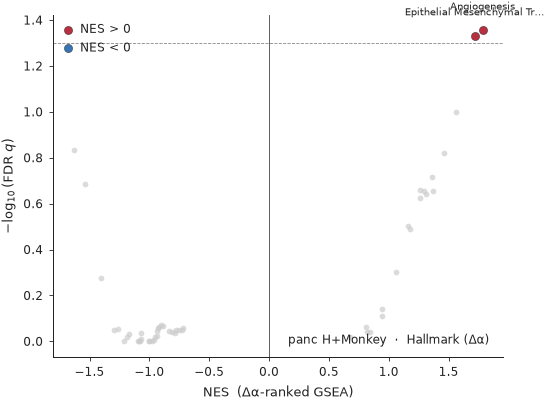

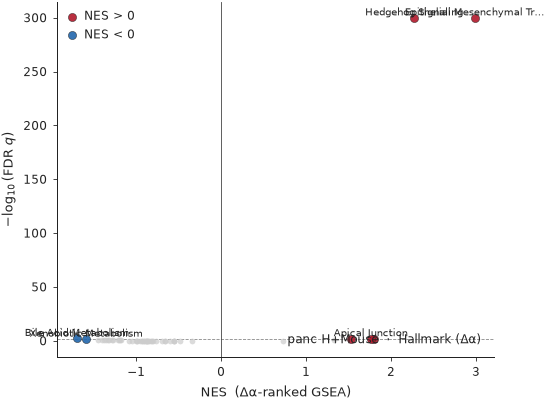

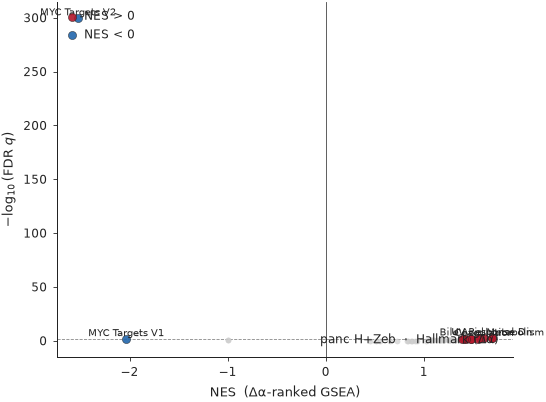

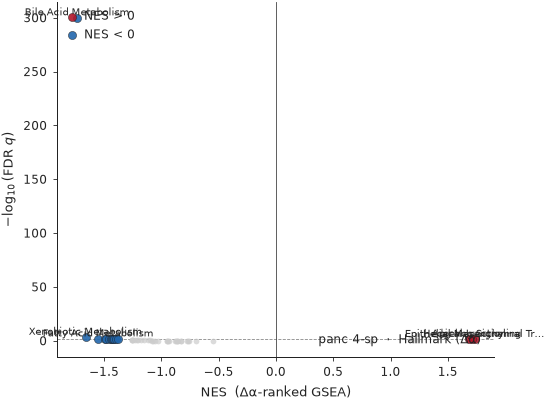

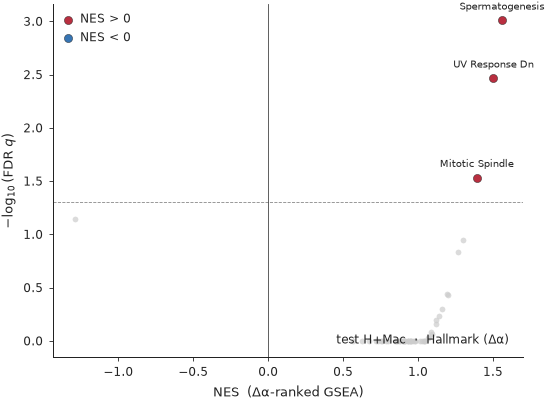

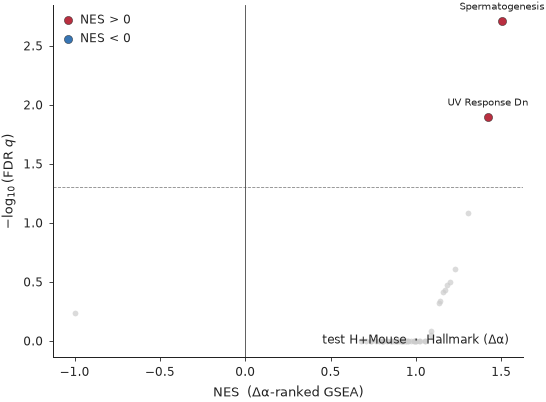

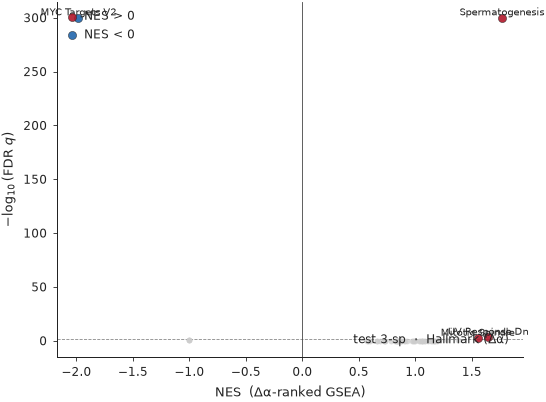

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


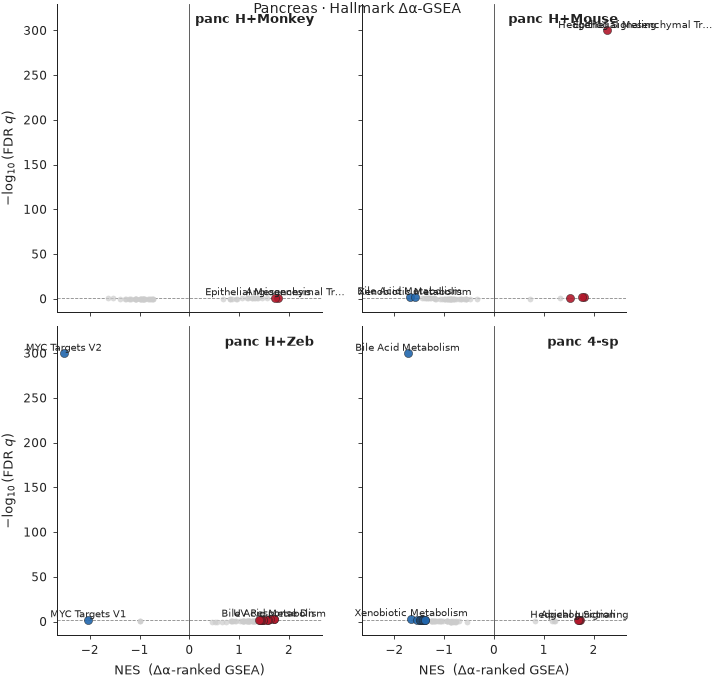

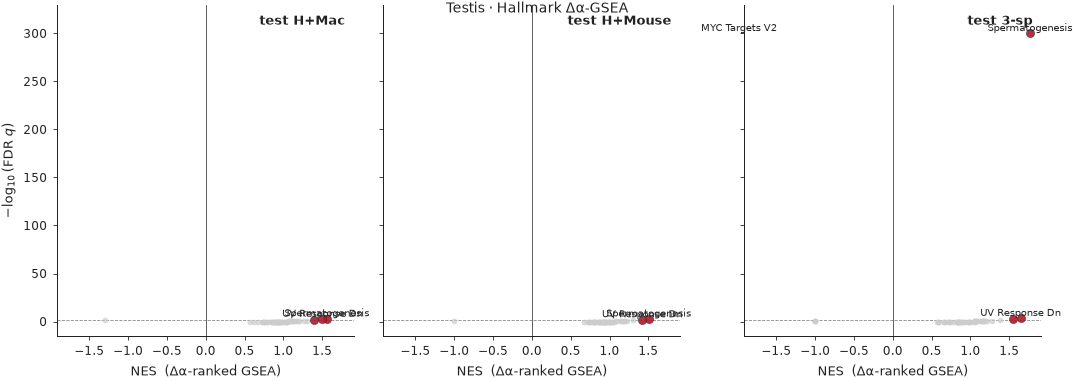

In [7]:
def _draw_volcano(ax, df, *, label_n: int = 2,
                  nes_lim: float | None = None,
                  nlf_max: float | None = None,
                  panel_id: str | None = None):
    d = df.copy()
    d["pathway"] = d["Term"].map(parse_pathway_name)
    d["nlog10_fdr"] = -np.log10(d["FDR q-val"].clip(1e-300, 1.0))
    d["sig"] = d["FDR q-val"] < FDR_THRESH

    ns = d[~d["sig"]]
    ax.scatter(ns["NES"], ns["nlog10_fdr"], s=12, c="#cccccc",
               alpha=0.7, linewidths=0, rasterized=True, zorder=1)
    sp = d[d["sig"] & (d["NES"] > 0)]
    sn = d[d["sig"] & (d["NES"] < 0)]
    ax.scatter(sp["NES"], sp["nlog10_fdr"], s=24, c="#b2182b",
               alpha=0.9, linewidths=0.3, edgecolor="#222222",
               rasterized=True, zorder=2, label="NES > 0")
    ax.scatter(sn["NES"], sn["nlog10_fdr"], s=24, c="#2166ac",
               alpha=0.9, linewidths=0.3, edgecolor="#222222",
               rasterized=True, zorder=2, label="NES < 0")
    ax.axhline(-np.log10(FDR_THRESH), color="#888888",
               linewidth=0.5, linestyle="--", zorder=0)
    ax.axvline(0, color="#444444", linewidth=0.5, zorder=0)
    for sub in (sp, sn):
        for _, r in sub.nlargest(label_n, "nlog10_fdr").iterrows():
            ax.text(r["NES"], r["nlog10_fdr"] + 0.08,
                    clean_pathway_name(r["pathway"], max_len=26),
                    fontsize=5.8, ha="center", va="bottom", color="#222222")
    if nes_lim is not None:
        ax.set_xlim(-1.05 * nes_lim, 1.05 * nes_lim)
    if nlf_max is not None:
        ax.set_ylim(-0.05 * nlf_max, 1.10 * nlf_max)
    if panel_id:
        ax.text(0.97, 0.97, panel_id, transform=ax.transAxes,
                ha="right", va="top", fontsize=8, color="#222222",
                fontweight="semibold")


def volcano_panel(df: pd.DataFrame, save_name: str, title: str,
                  xlabel: str = "NES  (Δα-ranked GSEA)"):
    fig, ax = fd.make_axes(figsize=(4.6, 3.4))
    _draw_volcano(ax, df, label_n=3)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$-\log_{10}(\mathrm{FDR}\;q)$")
    fd.thin_legend(ax, loc="upper left")
    fd.annotate_stat(ax, title, "lower right")
    fd.save_figure(fig, save_name)
    plt.show()


def volcano_grid(GSEA: dict, keys: list[str], save_name: str, *,
                 ncols: int, suptitle: str,
                 xlabel: str = "NES  (Δα-ranked GSEA)"):
    nrows, ncols_ = _tissue_grid_size(len(keys), ncols)
    # Shared axis ranges so panels are directly comparable.
    all_d = pd.concat([GSEA[k] for k in keys], ignore_index=True)
    nes_lim = float(np.nanpercentile(np.abs(all_d["NES"].values), 99.5))
    nlf_max = float(np.nanmax(
        -np.log10(all_d["FDR q-val"].clip(1e-300, 1.0))))
    if not np.isfinite(nes_lim) or nes_lim == 0: nes_lim = 2.5
    if not np.isfinite(nlf_max) or nlf_max == 0: nlf_max = 2.0

    fig, axes = plt.subplots(nrows, ncols_,
                              figsize=(3.0 * ncols_, 2.5 * nrows + 0.7),
                              layout="constrained", sharex=True, sharey=True)
    axes = np.atleast_2d(axes)
    for i, k in enumerate(keys):
        r, c = divmod(i, ncols_)
        ax = axes[r, c]
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        _draw_volcano(ax, GSEA[k], label_n=2, nes_lim=nes_lim,
                      nlf_max=nlf_max, panel_id=DATASETS[k]["label"])
        if r == nrows - 1:
            ax.set_xlabel(xlabel)
        if c == 0:
            ax.set_ylabel(r"$-\log_{10}(\mathrm{FDR}\;q)$")
    _hide_extra_axes(axes, len(keys))
    fig.suptitle(suptitle, fontsize=8.5, y=0.995)
    fd.save_figure(fig, save_name)
    plt.show()


# Per-dataset volcanoes (kept for supplements)
for k in DATASET_ORDER:
    volcano_panel(HALL_DELTA[k], f"A1_volcano_hallmark__{k}",
                  f"{DATASETS[k]['label']}  ·  Hallmark (Δα)")

# Tissue-grouped composites (paper-ready)
volcano_grid(HALL_DELTA, PANC_KEYS, "A1_volcano_hallmark_pancreas",
             ncols=2, suptitle="Pancreas · Hallmark Δα-GSEA")
volcano_grid(HALL_DELTA, TEST_KEYS, "A1_volcano_hallmark_testis",
             ncols=3, suptitle="Testis · Hallmark Δα-GSEA")


## §A.2 — Cross-dataset Hallmark NES heatmap (50 × 7) + tissue splits

Rows = Hallmark, columns = dataset. Cell colour = signed NES
(`RdBu_r`, diverging, symmetric). `FDR < 0.05` cells carry a
star. Rows ordered by **dataset-coverage of significant
same-sign hits** descending — the top of every heatmap is the
most reproducible Δα-Hallmark signature.

Three figures are written:

- `A2_hallmark_delta_nes_heatmap.pdf` — combined 50 × 7 with a
  visual tissue divider between `panc_4sp` and `test_hmac`
  and tissue-band labels above each column group.
- `A2_hallmark_nes_panc.pdf` — pancreas-only (50 × 4), row
  order shared with the combined heatmap so a side-by-side
  compare is one-to-one.
- `A2_hallmark_nes_test.pdf` — testis-only (50 × 3), same row
  ordering convention.


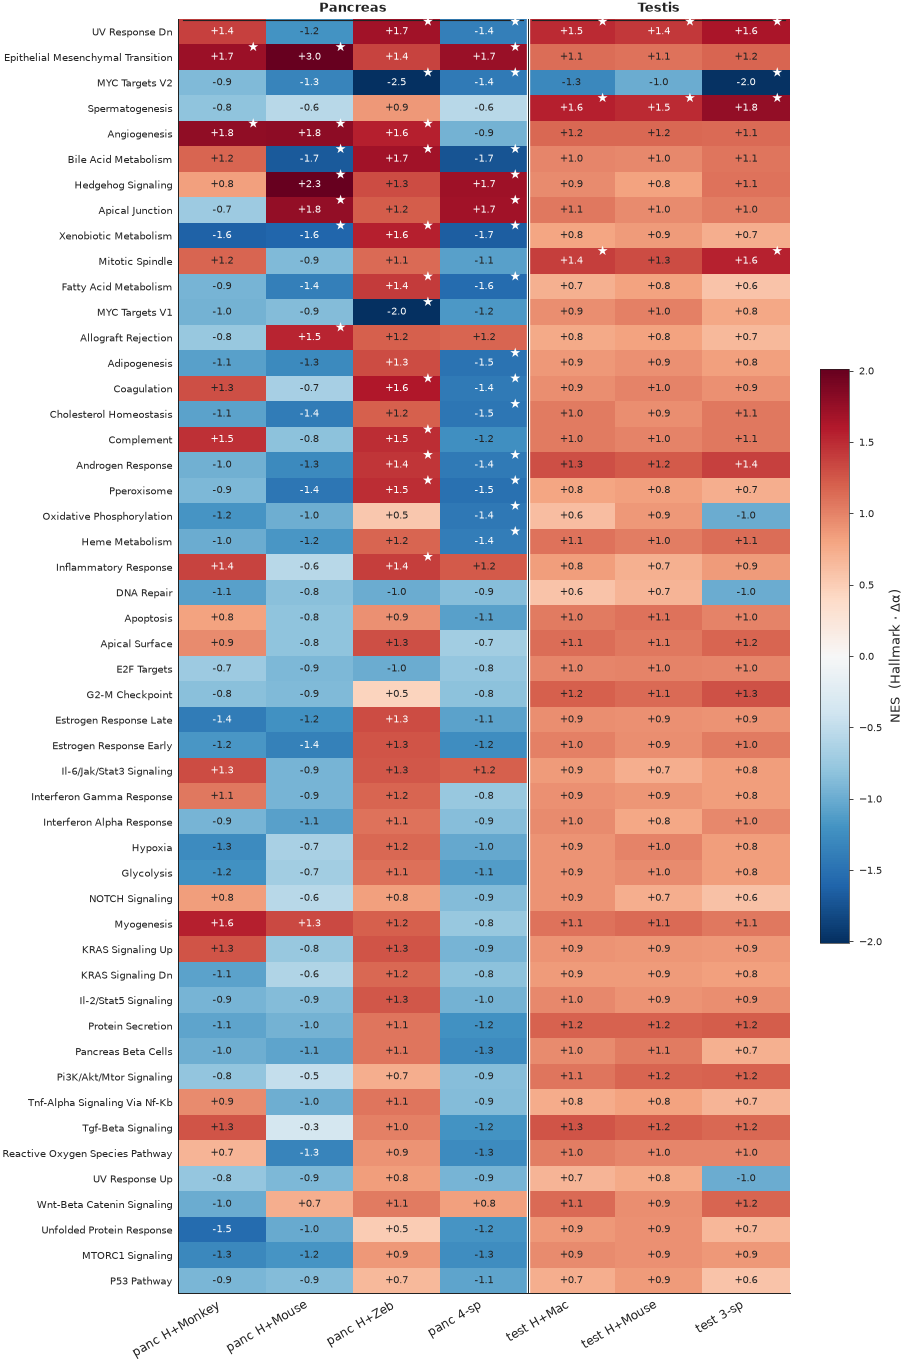

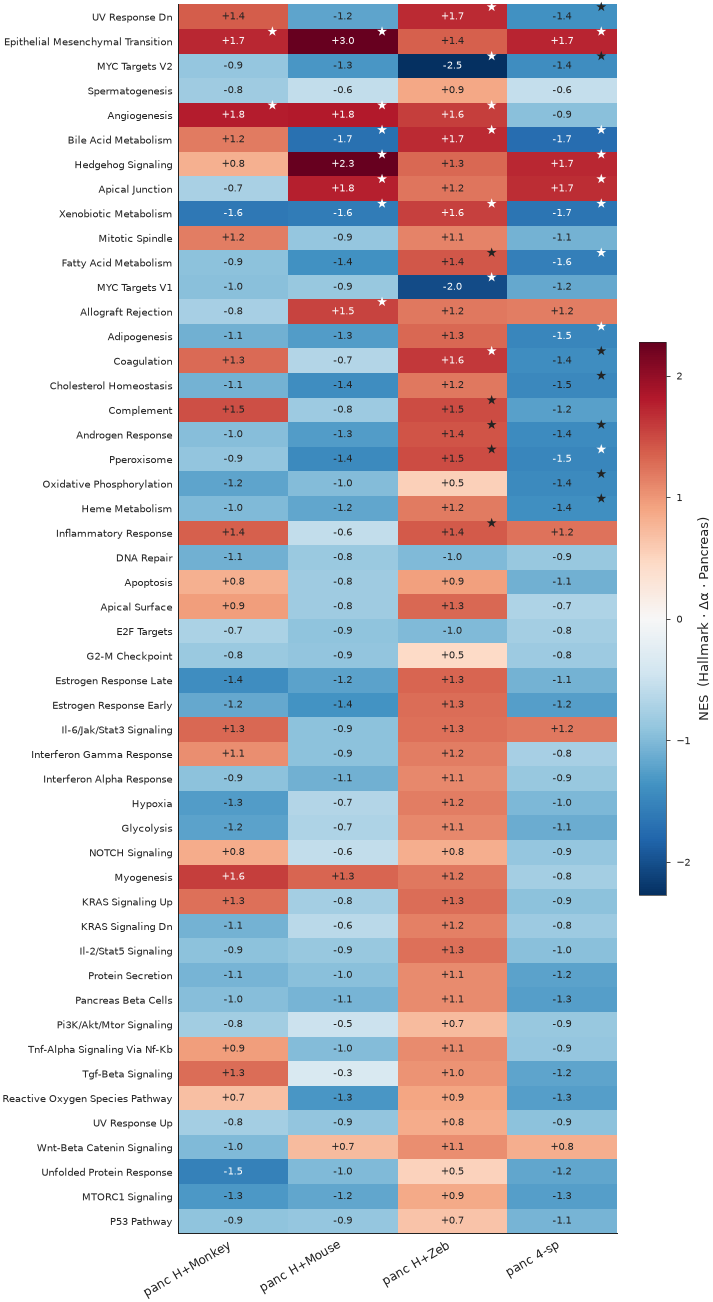

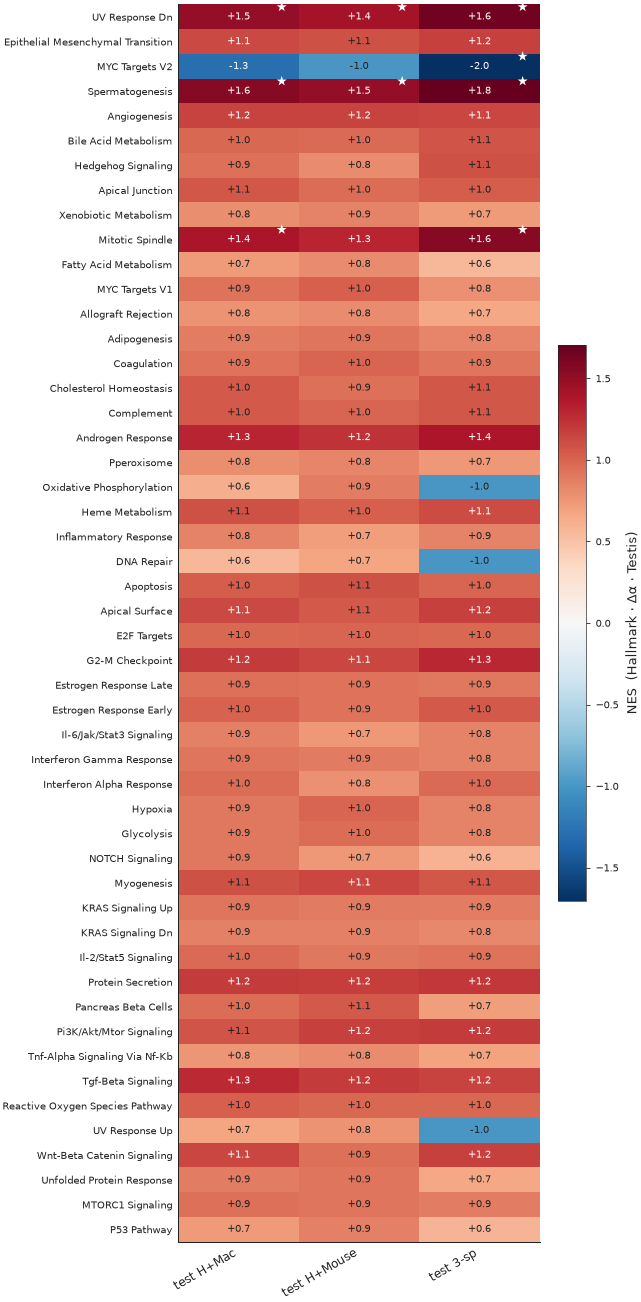


Most-reproducible Δα-Hallmark pathways (#datasets sig same-sign):
UV Response Dn                       4
Epithelial Mesenchymal Transition    3
Myc Targets V2                       3
Spermatogenesis                      3
Angiogenesis                         3
Bile Acid Metabolism                 2
Hedgehog Signaling                   2
Apical Junction                      2
Xenobiotic Metabolism                2
Mitotic Spindle                      2
Fatty Acid Metabolism                1
Myc Targets V1                       1
Allograft Rejection                  1
Adipogenesis                         1
Coagulation                          1


In [8]:
def _build_nes_pivot(GSEA: dict, keys: list[str]):
    rows = []
    for k in keys:
        df = GSEA[k].copy()
        df["pathway"] = df["Term"].map(parse_pathway_name)
        for _, r in df.iterrows():
            rows.append({
                "pathway": r["pathway"], "dataset": k,
                "NES": float(r["NES"]),
                "fdr": float(r["FDR q-val"]),
                "sig": float(r["FDR q-val"]) < FDR_THRESH,
            })
    long = pd.DataFrame(rows)
    nes = long.pivot(index="pathway", columns="dataset",
                      values="NES").reindex(columns=keys)
    sig = long.pivot(index="pathway", columns="dataset",
                      values="sig").reindex(columns=keys).fillna(False)
    return long, nes, sig


def _coverage(nes_row, sig_row) -> int:
    sig_signs = np.sign(nes_row.values[sig_row.values.astype(bool)])
    if len(sig_signs) == 0: return 0
    return int(max((sig_signs > 0).sum(), (sig_signs < 0).sum()))


def _heatmap_panel(nes_o: pd.DataFrame, sig_o: pd.DataFrame, *,
                   library_label: str, save_name: str,
                   tissue_divider_after: int | None = None,
                   tissue_band_labels: list[tuple[int, int, str]] | None = None,
                   fig_w: float = 7.4):
    n_rows = len(nes_o); n_cols = nes_o.shape[1]
    if n_rows == 0:
        print(f"  [{save_name}] no rows — skipping")
        return
    vmax = float(np.nanpercentile(np.abs(nes_o.values), 99))
    if not np.isfinite(vmax) or vmax == 0: vmax = 2.5

    cell_h = 0.20
    top_pad = 1.4 if tissue_band_labels else 0.9
    fig_h = cell_h * n_rows + top_pad
    fig, ax = plt.subplots(figsize=(fig_w, fig_h), layout="constrained")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    im = ax.imshow(nes_o.values, cmap="RdBu_r", aspect="auto",
                   vmin=-vmax, vmax=vmax)
    # Cell text (NES) + significance star at top-right corner of cell.
    for i in range(n_rows):
        for j in range(n_cols):
            v = nes_o.iloc[i, j]
            txt = "—" if not np.isfinite(v) else f"{v:+.1f}"
            tcolor = "#ffffff" if (np.isfinite(v) and abs(v) > 0.65 * vmax) else "#222222"
            ax.text(j, i, txt, ha="center", va="center",
                    fontsize=6.2, color=tcolor)
            if sig_o.iloc[i, j]:
                ax.text(j + 0.36, i - 0.36, "★", ha="center", va="center",
                        fontsize=7.5, color=tcolor)
    # Tissue divider: vertical white line between two column groups.
    if tissue_divider_after is not None:
        ax.axvline(tissue_divider_after + 0.5, color="#ffffff",
                   linewidth=2.0, zorder=10)
        ax.axvline(tissue_divider_after + 0.5, color="#222222",
                   linewidth=0.6, zorder=11)
    # Tissue band labels above columns.
    if tissue_band_labels:
        for j_lo, j_hi, lab in tissue_band_labels:
            xc = 0.5 * (j_lo + j_hi)
            ax.annotate(lab, xy=(xc, -0.65), xycoords="data",
                        ha="center", va="bottom", fontsize=8,
                        color="#222222", fontweight="semibold",
                        annotation_clip=False)
            ax.plot([j_lo - 0.45, j_hi + 0.45], [-0.45, -0.45],
                    color="#222222", linewidth=0.7,
                    clip_on=False, transform=ax.transData)
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels([DATASETS[k]["label"] for k in nes_o.columns],
                       rotation=30, ha="right", fontsize=7)
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels([clean_pathway_name(p, max_len=42)
                         for p in nes_o.index], fontsize=6.2)
    ax.tick_params(axis="x", length=0)
    ax.tick_params(axis="y", length=0)
    cb = fig.colorbar(im, ax=ax, label=f"NES  ({library_label})",
                      shrink=0.45)
    cb.ax.tick_params(labelsize=6)
    cb.outline.set_linewidth(0.4)
    fd.save_figure(fig, save_name)
    plt.show()


def cross_dataset_nes_heatmap(GSEA: dict, library_label: str,
                               save_name: str, top_k: int | None = None,
                               *, keys: list[str] | None = None,
                               ref_order=None,
                               tissue_divider_after: int | None = None,
                               tissue_band_labels=None,
                               fig_w: float = 7.4):
    keys = keys if keys is not None else DATASET_ORDER
    long, nes, sig = _build_nes_pivot(GSEA, keys)
    if ref_order is not None:
        order = [p for p in ref_order if p in nes.index]
    else:
        cov = pd.Series({p: _coverage(nes.loc[p], sig.loc[p])
                         for p in nes.index})
        order = list(cov.sort_values(ascending=False).index)
        if top_k is not None:
            order = order[:top_k]
    nes_o = nes.loc[order]; sig_o = sig.loc[order]
    _heatmap_panel(nes_o, sig_o, library_label=library_label,
                   save_name=save_name,
                   tissue_divider_after=tissue_divider_after,
                   tissue_band_labels=tissue_band_labels,
                   fig_w=fig_w)
    if ref_order is None:
        cov_full = pd.Series({p: _coverage(nes.loc[p], sig.loc[p])
                              for p in nes.index})
        return long, cov_full, order
    return long, None, order


# Combined (with tissue divider + bands)
HALLMARK_LONG, HALLMARK_COV, HALLMARK_ROW_ORDER = cross_dataset_nes_heatmap(
    HALL_DELTA, "Hallmark · Δα",
    "A2_hallmark_delta_nes_heatmap",
    tissue_divider_after=len(PANC_KEYS) - 1,
    tissue_band_labels=[
        (0, len(PANC_KEYS) - 1, "Pancreas"),
        (len(PANC_KEYS), len(DATASET_ORDER) - 1, "Testis"),
    ],
    fig_w=7.6)

# Tissue-split heatmaps — same row order so they line up with the combined.
cross_dataset_nes_heatmap(HALL_DELTA, "Hallmark · Δα · Pancreas",
    "A2_hallmark_nes_panc",
    keys=PANC_KEYS, ref_order=HALLMARK_ROW_ORDER, fig_w=6.0)
cross_dataset_nes_heatmap(HALL_DELTA, "Hallmark · Δα · Testis",
    "A2_hallmark_nes_test",
    keys=TEST_KEYS, ref_order=HALLMARK_ROW_ORDER, fig_w=5.4)

print(f"\nMost-reproducible Δα-Hallmark pathways (#datasets sig same-sign):")
print(HALLMARK_COV.sort_values(ascending=False).head(15).to_string())


# §B — Does Δα add information beyond the prior? *(the value-add panel)*

A skeptic reads §A and asks: "*Sure, Δα-GSEA reveals biology —
but is that biology the prior alone wouldn't have revealed? If
the prior already says ribosomal genes are conserved, NES on
those genes is unsurprising whether you rank by Δα or by prior.
Where is the Chimera-specific contribution?*"

§B answers that head-on. We re-run the same Hallmark GSEA but
now ranking each dataset's genes **by the conservation prior
alone** (pure sequence-identity-derived score, no GIN
involvement). Then we compare the two NES values per pathway:

- **Same-sign and similar magnitude** → Δα *amplifies* what the
  prior already showed (consistent biology).
- **Same-sign but Δα-only-significant** → Δα *recovers* signal
  that the prior was too compressed to flag at FDR < 0.05.
- **Δα significant, prior not** → **Chimera-unique discovery:
  pathway flagged only because Δα captured regulatory
  conservation the prior couldn't see**.
- **Opposite-sign** → **regulatory rewiring**: the prior says
  "this pathway has conserved sequences", Δα says "but the
  regulation is *more divergent than sequences predict*"
  (or vice versa). The strongest Chimera-specific call.

This section quantifies how often each quadrant is populated —
and which Hallmarks live there.


In [9]:
print("running prior-Hallmark GSEA per dataset (cached after first run)…")
HALL_PRIOR = {k: gsea_for(k, LIB_HALLMARK, metric="prior")
              for k in DATASET_ORDER}
print("done.")


running prior-Hallmark GSEA per dataset (cached after first run)…


done.


## §B.1 — Per-dataset NES scatter: prior vs Δα

One panel per dataset. x = NES from prior-ranked GSEA;
y = NES from Δα-ranked GSEA. Each dot = one Hallmark.

- Diagonal = Δα and prior agree (magnitude *and* sign).
- Lower-left / upper-right (off-diagonal, same-sign) =
  Chimera **amplifies** what the prior already showed.
- Upper-left / lower-right (opposite-sign) = **regulatory
  rewiring** — the most Chimera-specific call.
- High |Δα-NES| with low |prior-NES| = **Δα-unique signal**.

Marker fill encodes Δα significance (red = sig & NES > 0,
blue = sig & NES < 0, gray = NS in Δα). Marker edge encodes
prior-significance (black border = prior `FDR < 0.05`).

**Two paper-ready composites:** `B1_scatter_prior_vs_delta_pancreas.pdf`
(2×2) and `B1_scatter_prior_vs_delta_testis.pdf` (1×3). The
7 individual single-panel PDFs are also written for supplements.


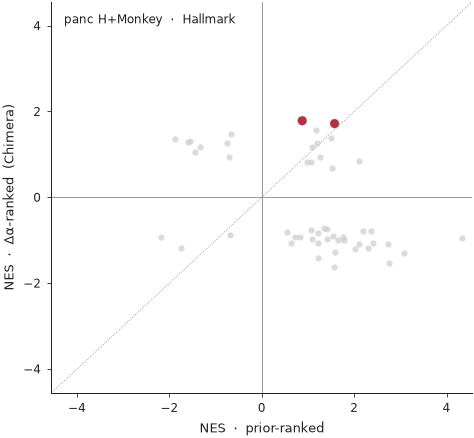

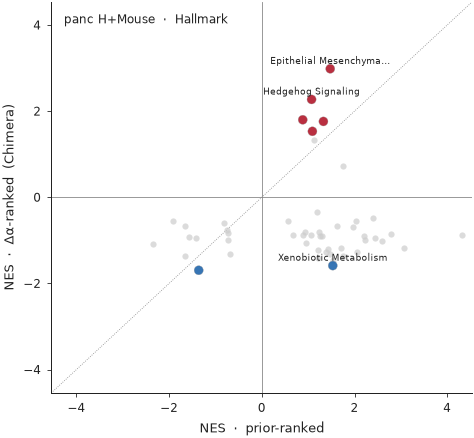

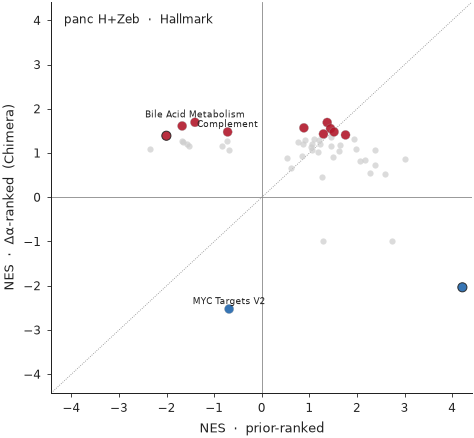

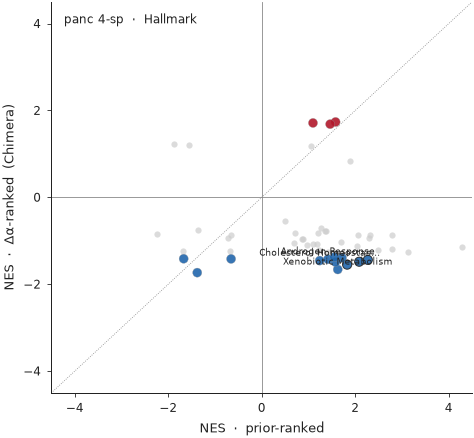

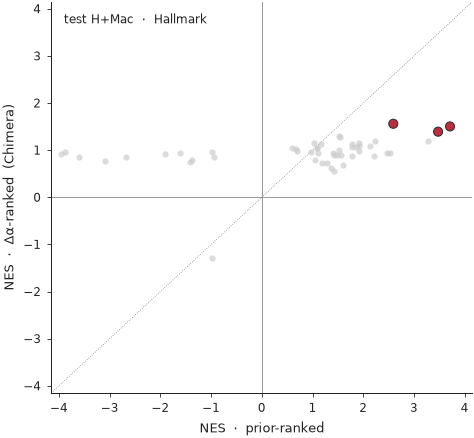

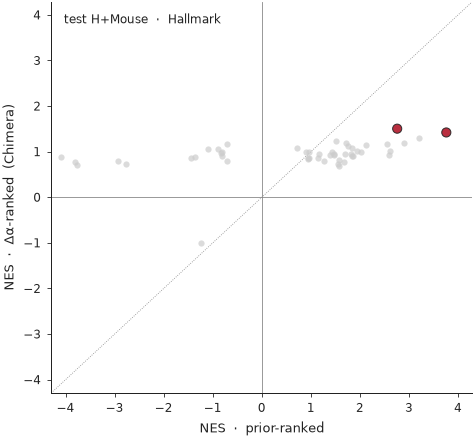

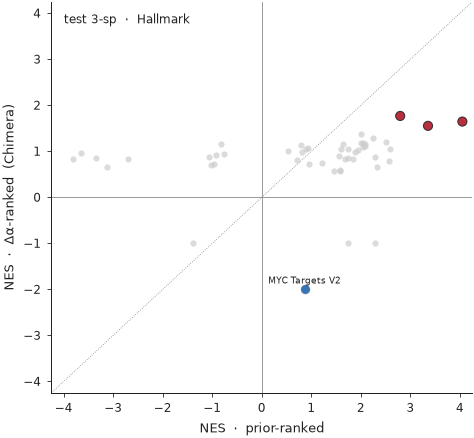

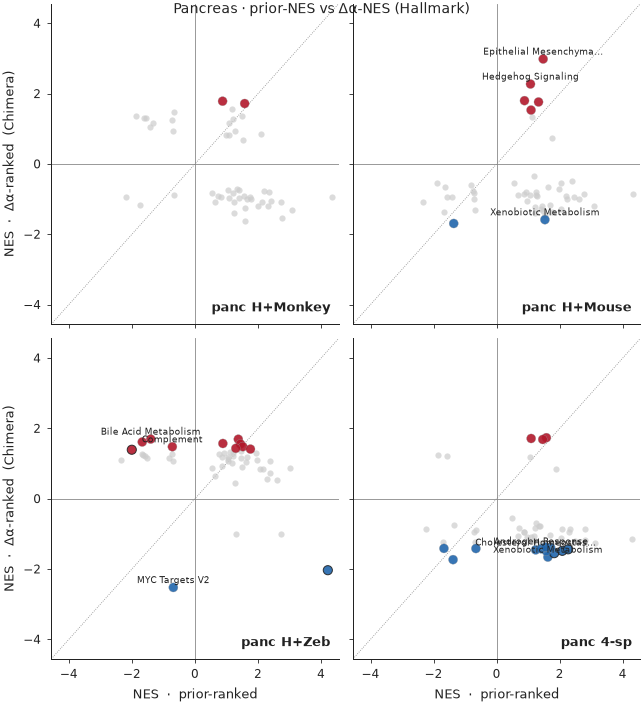

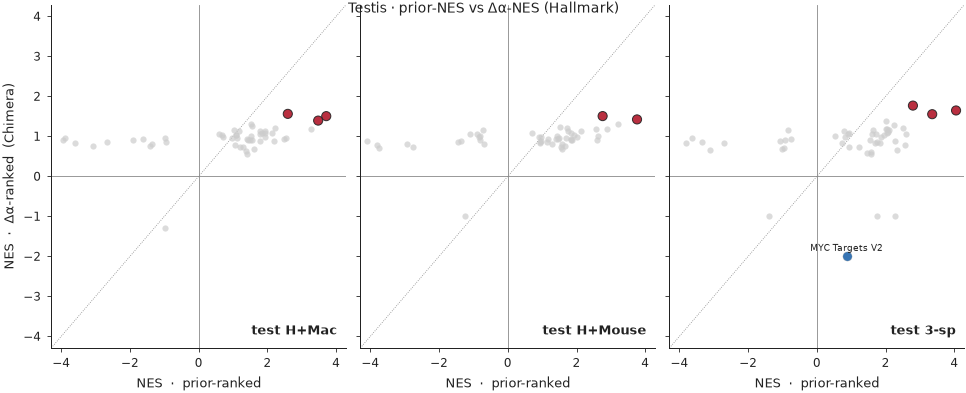

In [10]:
def _draw_prior_vs_delta_scatter(ax, key: str, *, label_n: int = 4,
                                 lim: float | None = None,
                                 panel_id: str | None = None):
    d = HALL_DELTA[key].copy()
    p = HALL_PRIOR[key].copy()
    d["pathway"] = d["Term"].map(parse_pathway_name)
    p["pathway"] = p["Term"].map(parse_pathway_name)
    merged = d.merge(p, on="pathway", suffixes=("_delta", "_prior"))
    merged["sig_delta"] = merged["FDR q-val_delta"] < FDR_THRESH
    merged["sig_prior"] = merged["FDR q-val_prior"] < FDR_THRESH

    if lim is None:
        lim_max = float(np.nanmax(
            np.abs(merged[["NES_delta", "NES_prior"]].values)))
        if not np.isfinite(lim_max) or lim_max == 0: lim_max = 2.5
        lim = 1.05 * lim_max

    ax.axhline(0, color="#888888", linewidth=0.5, zorder=0)
    ax.axvline(0, color="#888888", linewidth=0.5, zorder=0)
    ax.plot([-lim, lim], [-lim, lim], color="#888888",
            linewidth=0.5, linestyle=":", zorder=0)

    ns = merged[~merged["sig_delta"]]
    ax.scatter(ns["NES_prior"], ns["NES_delta"],
               s=14, c="#cccccc", alpha=0.7, linewidths=0,
               rasterized=True, zorder=1)
    sd_pos = merged[merged["sig_delta"] & (merged["NES_delta"] > 0)]
    sd_neg = merged[merged["sig_delta"] & (merged["NES_delta"] < 0)]
    for sub, color in [(sd_pos, "#b2182b"), (sd_neg, "#2166ac")]:
        ec = np.where(sub["sig_prior"], "#222222", "#999999")
        lw = np.where(sub["sig_prior"], 0.6, 0.2)
        ax.scatter(sub["NES_prior"], sub["NES_delta"], s=30, c=color,
                   alpha=0.9, edgecolors=ec, linewidths=lw,
                   rasterized=True, zorder=2)
    # Chimera-specific labelling (opposite sign or |Δα|≫|prior|)
    merged["chimera_specificity"] = (
        np.abs(merged["NES_delta"]) - 0.5 * np.abs(merged["NES_prior"])
    ) + 0.7 * (np.sign(merged["NES_delta"]) !=
               np.sign(merged["NES_prior"])).astype(float)
    for _, r in merged.nlargest(label_n, "chimera_specificity").iterrows():
        if r["sig_delta"]:
            ax.text(r["NES_prior"], r["NES_delta"] + 0.06,
                    clean_pathway_name(r["pathway"], max_len=22),
                    fontsize=5.6, ha="center", va="bottom", color="#222222")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    if panel_id:
        ax.text(0.97, 0.03, panel_id, transform=ax.transAxes,
                ha="right", va="bottom", fontsize=8, color="#222222",
                fontweight="semibold")
    return lim


def plot_nes_scatter(key: str, save_name: str):
    fig, ax = fd.make_axes(figsize=(4.0, 3.7))
    _draw_prior_vs_delta_scatter(ax, key, label_n=4)
    ax.set_xlabel("NES  ·  prior-ranked")
    ax.set_ylabel("NES  ·  Δα-ranked  (Chimera)")
    fd.annotate_stat(ax, f"{DATASETS[key]['label']}  ·  Hallmark",
                     "upper left")
    fd.save_figure(fig, save_name)
    plt.show()


def scatter_grid(keys: list[str], save_name: str, *,
                 ncols: int, suptitle: str):
    nrows, ncols_ = _tissue_grid_size(len(keys), ncols)
    # shared axis range across panels in the composite
    all_lim = 0.0
    for k in keys:
        d = HALL_DELTA[k]; p = HALL_PRIOR[k]
        all_lim = max(all_lim,
                      float(np.nanmax(np.abs(d["NES"].values))),
                      float(np.nanmax(np.abs(p["NES"].values))))
    if not np.isfinite(all_lim) or all_lim == 0: all_lim = 2.5
    lim = 1.05 * all_lim

    fig, axes = plt.subplots(nrows, ncols_,
                              figsize=(2.7 * ncols_, 2.6 * nrows + 0.7),
                              layout="constrained", sharex=True, sharey=True)
    axes = np.atleast_2d(axes)
    for i, k in enumerate(keys):
        r, c = divmod(i, ncols_)
        ax = axes[r, c]
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        _draw_prior_vs_delta_scatter(ax, k, label_n=3, lim=lim,
                                     panel_id=DATASETS[k]["label"])
        if r == nrows - 1:
            ax.set_xlabel("NES  ·  prior-ranked")
        if c == 0:
            ax.set_ylabel("NES  ·  Δα-ranked  (Chimera)")
    _hide_extra_axes(axes, len(keys))
    fig.suptitle(suptitle, fontsize=8.5, y=0.995)
    fd.save_figure(fig, save_name)
    plt.show()


# Per-dataset (kept for supplements)
for k in DATASET_ORDER:
    plot_nes_scatter(k, f"B1_nes_scatter_prior_vs_delta__{k}")

# Tissue-grouped composites
scatter_grid(PANC_KEYS, "B1_scatter_prior_vs_delta_pancreas",
             ncols=2, suptitle="Pancreas · prior-NES vs Δα-NES (Hallmark)")
scatter_grid(TEST_KEYS, "B1_scatter_prior_vs_delta_testis",
             ncols=3, suptitle="Testis · prior-NES vs Δα-NES (Hallmark)")


## §B.2 — How many Hallmarks does Δα add per dataset?

For each dataset, count Hallmarks in four exclusive bins:

- `prior-only` significant (Δα misses)
- `both` significant, same direction (Δα *confirms* + amplifies)
- `Δα-only` significant (Chimera adds)
- `both` significant, opposite direction (**regulatory rewiring**)

Stacked-bar chart per dataset, grouped visually by organ. The
taller the **Δα-only** + **opposite-direction** segments, the
more Chimera adds beyond the prior on that dataset.

Two figures:

- `B2_quadrant_stack_hallmark.pdf` — combined 7-bar layout with
  visible gap and tissue-band labels separating Pancreas / Testis.
- `B2_quadrant_stack_hallmark_tissue.pdf` — paper-ready 2-panel
  side-by-side (Pancreas | Testis) with shared y-axis.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


              prior_only  delta_only  both_same  both_opp  n_pathways
dataset                                                              
panc_hmonkey          13           2          0         0          50
panc_hmouse           13           7          0         0          50
panc_hzeb             11          10          0         2          50
panc_4sp              12          12          0         3          50
test_hmac             19           0          3         0          50
test_hmouse           18           0          2         0          50
test_3sp              25           1          3         0          50


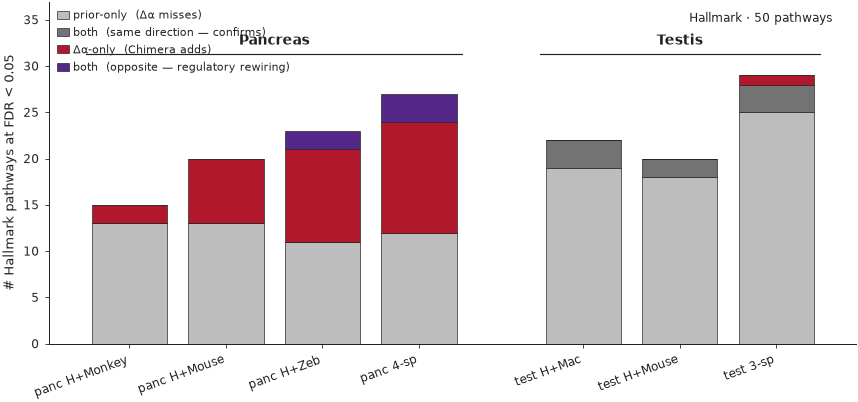

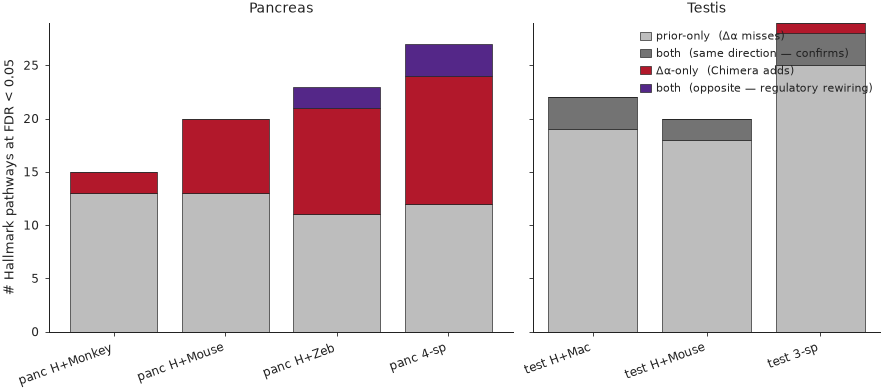

In [11]:
def quadrant_counts(d: pd.DataFrame, p: pd.DataFrame) -> dict:
    d = d.copy(); p = p.copy()
    d["pathway"] = d["Term"].map(parse_pathway_name)
    p["pathway"] = p["Term"].map(parse_pathway_name)
    m = d.merge(p, on="pathway", suffixes=("_d","_p"))
    sd = m["FDR q-val_d"] < FDR_THRESH
    sp = m["FDR q-val_p"] < FDR_THRESH
    same = np.sign(m["NES_d"]) == np.sign(m["NES_p"])
    return dict(
        prior_only=int(((~sd) & sp).sum()),
        delta_only=int((sd & (~sp)).sum()),
        both_same=int((sd & sp & same).sum()),
        both_opp =int((sd & sp & (~same)).sum()),
        n_pathways=int(len(m)),
    )

qrows = []
for k in DATASET_ORDER:
    q = quadrant_counts(HALL_DELTA[k], HALL_PRIOR[k])
    q["dataset"] = k; qrows.append(q)
qdf = pd.DataFrame(qrows).set_index("dataset").loc[DATASET_ORDER]
print(qdf.to_string())


QUAD_LABELS = {
    "prior_only": "prior-only  (Δα misses)",
    "both_same":  "both  (same direction — confirms)",
    "delta_only": "Δα-only  (Chimera adds)",
    "both_opp":   "both  (opposite — regulatory rewiring)",
}
QUAD_COLORS = {
    "prior_only": "#bdbdbd",
    "both_same":  "#737373",
    "delta_only": "#b2182b",
    "both_opp":   "#542788",
}
QUAD_ORDER = ["prior_only", "both_same", "delta_only", "both_opp"]


def _stack_bars(ax, keys, *, x_offset: int = 0, x_step: float = 1.0):
    x = np.arange(len(keys)) * x_step + x_offset
    bottom = np.zeros(len(keys))
    for q in QUAD_ORDER:
        v = qdf.loc[keys, q].values
        ax.bar(x, v, bottom=bottom, label=QUAD_LABELS[q],
               color=QUAD_COLORS[q], edgecolor="#222222",
               linewidth=0.4, width=0.78)
        bottom = bottom + v
    return x, bottom


# ---------- combined (one figure, with tissue gap) ----------
fig, ax = fd.make_axes(figsize=(7.2, 3.4))
x_panc, top_panc = _stack_bars(ax, PANC_KEYS, x_offset=0)
GAP = 0.7
x_test, top_test = _stack_bars(ax, TEST_KEYS,
                                x_offset=len(PANC_KEYS) + GAP)
x_all = np.concatenate([x_panc, x_test])
ax.set_xticks(x_all)
ax.set_xticklabels([DATASETS[k]["label"] for k in DATASET_ORDER],
                   rotation=20, ha="right", fontsize=7)
ax.set_ylabel("# Hallmark pathways at FDR < 0.05")
# Tissue band labels above each group
ymax = max(top_panc.max(), top_test.max())
band_y = ymax * 1.08
for label, xs in [("Pancreas", x_panc), ("Testis", x_test)]:
    x_lo, x_hi = xs.min() - 0.45, xs.max() + 0.45
    ax.plot([x_lo, x_hi], [band_y, band_y],
            color="#222222", linewidth=0.7, clip_on=False)
    ax.text(0.5 * (x_lo + x_hi), band_y * 1.02, label,
            ha="center", va="bottom", fontsize=8.5,
            color="#222222", fontweight="semibold", clip_on=False)
ax.set_ylim(0, band_y * 1.18)
# De-duplicate legend (we drew the same labels twice)
h, l = ax.get_legend_handles_labels()
seen = set(); h2, l2 = [], []
for hh, ll in zip(h, l):
    if ll in seen: continue
    seen.add(ll); h2.append(hh); l2.append(ll)
ax.legend(h2, l2, loc="upper left", frameon=False, fontsize=6.8,
          handlelength=1.0, handletextpad=0.4, borderpad=0.2)
fd.annotate_stat(ax, "Hallmark · 50 pathways", "upper right")
fd.save_figure(fig, "B2_quadrant_stack_hallmark")
plt.show()


# ---------- 2-panel tissue-split ----------
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.3),
                          gridspec_kw=dict(width_ratios=[len(PANC_KEYS),
                                                          len(TEST_KEYS)]),
                          sharey=True, layout="constrained")
for ax, keys, title in zip(
    axes, [PANC_KEYS, TEST_KEYS], ["Pancreas", "Testis"]
):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    _stack_bars(ax, keys, x_offset=0)
    ax.set_xticks(np.arange(len(keys)))
    ax.set_xticklabels([DATASETS[k]["label"] for k in keys],
                       rotation=20, ha="right", fontsize=7)
    ax.set_title(title, fontsize=8.5, color="#222222")
axes[0].set_ylabel("# Hallmark pathways at FDR < 0.05")
# Single legend on the rightmost panel.
h, l = axes[-1].get_legend_handles_labels()
seen = set(); h2, l2 = [], []
for hh, ll in zip(h, l):
    if ll in seen: continue
    seen.add(ll); h2.append(hh); l2.append(ll)
axes[-1].legend(h2, l2, loc="upper right", frameon=False, fontsize=6.8,
                handlelength=1.0, handletextpad=0.4, borderpad=0.2)
fd.save_figure(fig, "B2_quadrant_stack_hallmark_tissue")
plt.show()


## §B.3 — *Which* Hallmarks is Δα uniquely flagging?

For each dataset, list the Hallmark pathways that are
significant in Δα-GSEA but *not* in prior-GSEA — the
Chimera-unique calls — plus any *opposite-sign* hits
(regulatory rewiring). These are the pathways that justify
feeding the GIN with sequence: it learned *something the
sequence prior alone didn't say*. CSV per dataset under
`runs/<run>/tables/gsea_chimera_unique.csv`.


In [12]:
def chimera_unique_calls(key: str) -> pd.DataFrame:
    d = HALL_DELTA[key].copy(); p = HALL_PRIOR[key].copy()
    d["pathway"] = d["Term"].map(parse_pathway_name)
    p["pathway"] = p["Term"].map(parse_pathway_name)
    m = d.merge(p, on="pathway", suffixes=("_delta","_prior"))
    m = m.rename(columns={
        "NES_delta": "NES_delta", "NES_prior": "NES_prior",
        "FDR q-val_delta": "FDR_delta",
        "FDR q-val_prior": "FDR_prior",
        "Lead_genes_delta": "leading_edge_delta",
    })
    m["sig_delta"] = m["FDR_delta"] < FDR_THRESH
    m["sig_prior"] = m["FDR_prior"] < FDR_THRESH
    m["same_sign"] = np.sign(m["NES_delta"]) == np.sign(m["NES_prior"])
    m["call"] = "ns"
    m.loc[m["sig_delta"] & (~m["sig_prior"]), "call"] = "delta_only"
    m.loc[m["sig_delta"] &  m["sig_prior"]  & ( m["same_sign"]), "call"] = "both_same"
    m.loc[m["sig_delta"] &  m["sig_prior"]  & (~m["same_sign"]), "call"] = "both_opposite"
    m.loc[(~m["sig_delta"]) & m["sig_prior"], "call"] = "prior_only"
    out = m[m["call"].isin(["delta_only","both_opposite"])][[
        "pathway","call","NES_delta","NES_prior","FDR_delta","FDR_prior",
        "leading_edge_delta",
    ]].sort_values("call").sort_values(
        "NES_delta", key=lambda s: -np.abs(s))
    return out


for k in DATASET_ORDER:
    out = chimera_unique_calls(k)
    out_dir = RUNS_ROOT / DATASETS[k]["name"] / "tables"
    out_dir.mkdir(parents=True, exist_ok=True)
    out.to_csv(out_dir / "gsea_chimera_unique.csv", index=False)
    print(f"\n=== {DATASETS[k]['label']}  ·  Chimera-unique Hallmark calls ===")
    if len(out) == 0:
        print("  (none beyond what the prior already flagged)")
        continue
    for _, r in out.iterrows():
        tag = ("Δα-ONLY"     if r["call"] == "delta_only"
               else "REWIRING")
        print(f"  [{tag:8s}]  {r['pathway']:32s}  "
              f"NES_Δα={r['NES_delta']:+.2f}  "
              f"NES_prior={r['NES_prior']:+.2f}  "
              f"FDR_Δα={r['FDR_delta']:.2g}")



=== panc H+Monkey  ·  Chimera-unique Hallmark calls ===
  [Δα-ONLY ]  Angiogenesis                      NES_Δα=+1.78  NES_prior=+0.87  FDR_Δα=0.044
  [Δα-ONLY ]  Epithelial Mesenchymal Transition  NES_Δα=+1.72  NES_prior=+1.58  FDR_Δα=0.047

=== panc H+Mouse  ·  Chimera-unique Hallmark calls ===
  [Δα-ONLY ]  Epithelial Mesenchymal Transition  NES_Δα=+2.98  NES_prior=+1.48  FDR_Δα=0
  [Δα-ONLY ]  Hedgehog Signaling                NES_Δα=+2.27  NES_prior=+1.07  FDR_Δα=0
  [Δα-ONLY ]  Angiogenesis                      NES_Δα=+1.80  NES_prior=+0.88  FDR_Δα=0.012
  [Δα-ONLY ]  Apical Junction                   NES_Δα=+1.76  NES_prior=+1.33  FDR_Δα=0.0094
  [Δα-ONLY ]  Bile Acid Metabolism              NES_Δα=-1.70  NES_prior=-1.36  FDR_Δα=0.0053
  [Δα-ONLY ]  Xenobiotic Metabolism             NES_Δα=-1.59  NES_prior=+1.53  FDR_Δα=0.026
  [Δα-ONLY ]  Allograft Rejection               NES_Δα=+1.53  NES_prior=+1.09  FDR_Δα=0.043

=== panc H+Zeb  ·  Chimera-unique Hallmark calls ===
  [Δα-ONL


=== test 3-sp  ·  Chimera-unique Hallmark calls ===
  [Δα-ONLY ]  Myc Targets V2                    NES_Δα=-1.98  NES_prior=+0.86  FDR_Δα=0


# §C — Higher resolution: Reactome 2024

Hallmark gives a 50-pathway view of biology, paper-friendly but
coarse. Reactome 2024 (~2 000 pathways) resolves the same
territory at process level. Where Hallmark says
*OXIDATIVE_PHOSPHORYLATION*, Reactome separates it into
*Respiratory ETC*, *ATP synthesis*, *TCA cycle*, *Complex I
biogenesis*, … and Chimera's signed-Δα GSEA can disagree
between sub-processes that Hallmark fuses.

The ~2 000 hypothesis space brings a heavier multiple-testing
burden, so we trim the cross-dataset heatmap to the top-K
most-reproducible (top-K by dataset-coverage of significant
same-sign hits). Pathways that survive this filter are the
granular biology Chimera surfaces.


In [13]:
print("running Δα-Reactome GSEA per dataset (cached after first run)…")
REACTOME = {k: gsea_for(k, LIB_REACTOME, metric="delta")
            for k in DATASET_ORDER}
print("done.")


running Δα-Reactome GSEA per dataset (cached after first run)…


done.


## §C.1 — Cross-dataset Reactome NES heatmap (top-40 reproducible) + tissue splits

Three figures, same convention as §A.2:

- `C1_reactome_nes_heatmap.pdf` — combined top-40 with tissue
  divider + tissue-band labels.
- `C1_reactome_nes_panc.pdf` — pancreas-only, sharing the
  combined heatmap's row order.
- `C1_reactome_nes_test.pdf` — testis-only, same convention.


/tmp/ipykernel_488923/3920971749.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values="sig").reindex(columns=keys).fillna(False)


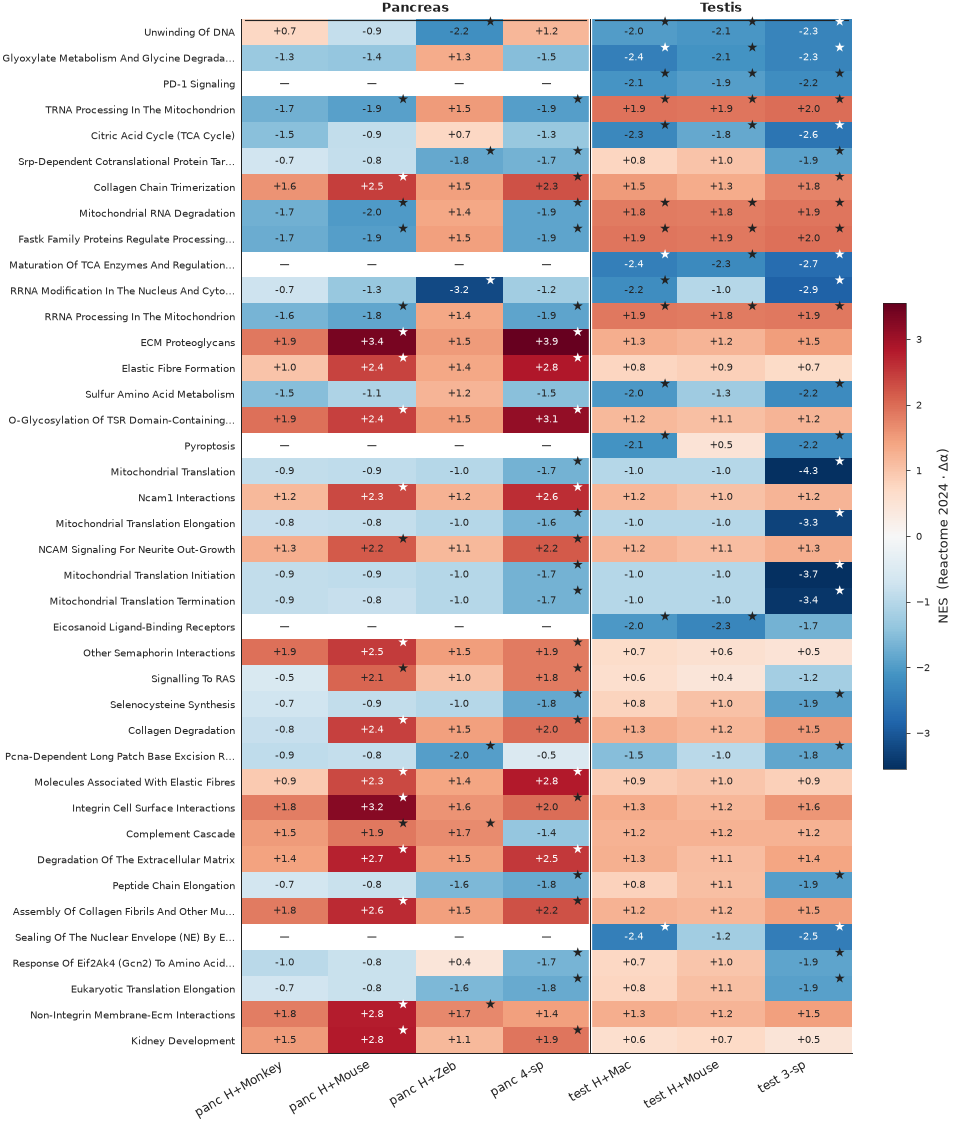

/tmp/ipykernel_488923/3920971749.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values="sig").reindex(columns=keys).fillna(False)


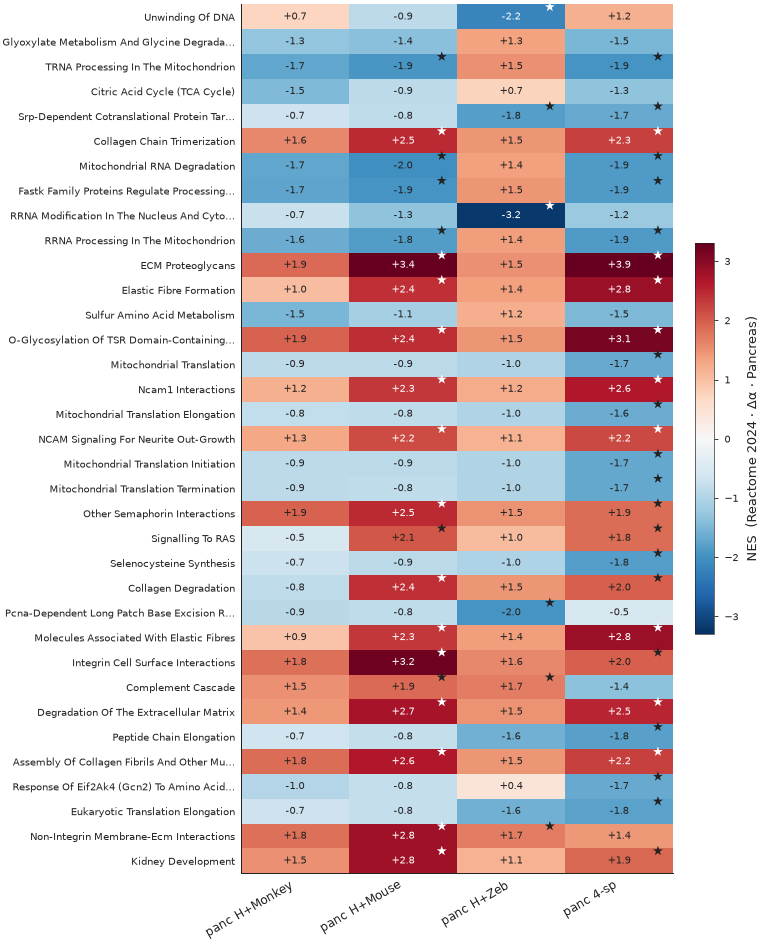

/tmp/ipykernel_488923/3920971749.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values="sig").reindex(columns=keys).fillna(False)


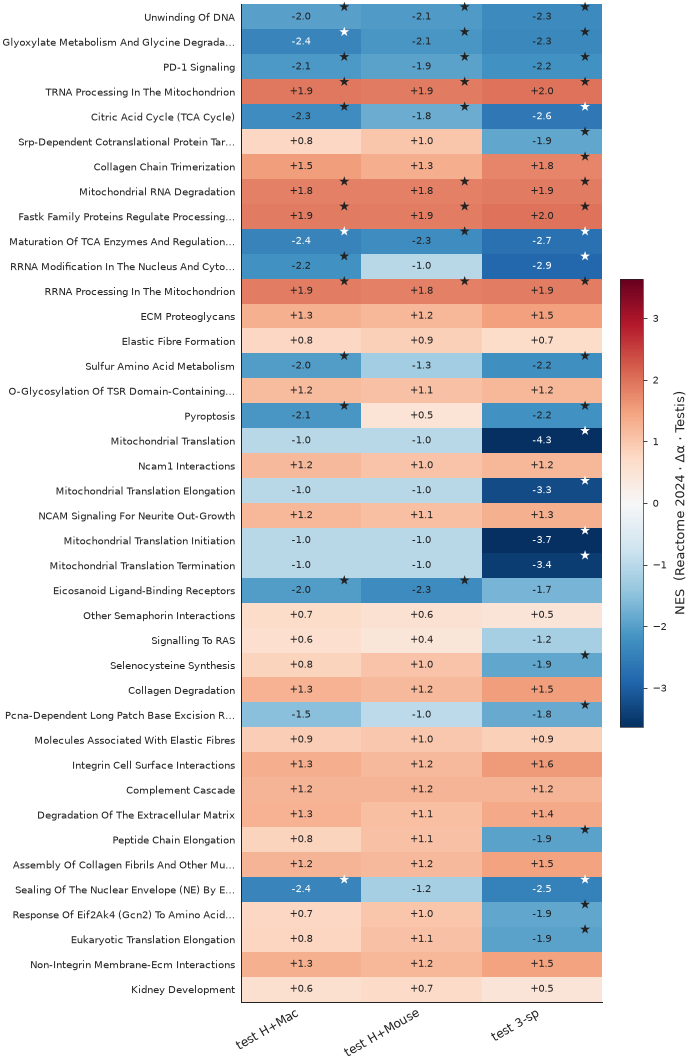


Most-reproducible Δα-Reactome pathways (#datasets sig same-sign):
Unwinding of DNA                                                                 4
Glyoxylate Metabolism and Glycine Degradation                                    3
PD-1 Signaling                                                                   3
tRNA Processing in the Mitochondrion                                             3
Citric Acid Cycle (TCA Cycle)                                                    3
SRP-dependent Cotranslational Protein Targeting to Membrane                      3
Collagen Chain Trimerization                                                     3
Mitochondrial RNA Degradation                                                    3
FASTK Family Proteins Regulate Processing and Stability of Mitochondrial RNAs    3
Maturation of TCA Enzymes and Regulation of TCA Cycle                            3
rRNA Modification in the Nucleus and Cytosol                                     3
rRNA Processing in t

In [14]:
REACTOME_LONG, REACTOME_COV, REACTOME_ROW_ORDER = cross_dataset_nes_heatmap(
    REACTOME, "Reactome 2024 · Δα",
    "C1_reactome_nes_heatmap", top_k=40,
    tissue_divider_after=len(PANC_KEYS) - 1,
    tissue_band_labels=[
        (0, len(PANC_KEYS) - 1, "Pancreas"),
        (len(PANC_KEYS), len(DATASET_ORDER) - 1, "Testis"),
    ],
    fig_w=8.0)

cross_dataset_nes_heatmap(REACTOME, "Reactome 2024 · Δα · Pancreas",
    "C1_reactome_nes_panc",
    keys=PANC_KEYS, ref_order=REACTOME_ROW_ORDER, fig_w=6.4)
cross_dataset_nes_heatmap(REACTOME, "Reactome 2024 · Δα · Testis",
    "C1_reactome_nes_test",
    keys=TEST_KEYS, ref_order=REACTOME_ROW_ORDER, fig_w=5.8)

print(f"\nMost-reproducible Δα-Reactome pathways (#datasets sig same-sign):")
print(REACTOME_COV.sort_values(ascending=False).head(20).to_string())


## §C.2 — Leading-edge gene tables (top reproducible Reactome hits)

For each of the top-10 most-reproducible Reactome pathways,
dump leading-edge genes per dataset to CSV under each run-dir's
`tables/`. The leading-edge subset drives the enrichment — the
genes a reader can quote.


In [15]:
def dump_leading_edge(GSEA: dict, library_short: str, top_paths: list[str]):
    for k in DATASET_ORDER:
        df = GSEA[k].copy()
        df["pathway"] = df["Term"].map(parse_pathway_name)
        sub = df[df["pathway"].isin(top_paths)].copy()
        sub = sub[["pathway", "NES", "FDR q-val", "Lead_genes"]]
        sub.columns = ["pathway", "NES", "FDR_q", "leading_edge"]
        out_dir = RUNS_ROOT / DATASETS[k]["name"] / "tables"
        out_dir.mkdir(parents=True, exist_ok=True)
        out = out_dir / f"gsea_lead__{library_short}.csv"
        sub.to_csv(out, index=False)


top_reactome = REACTOME_COV.sort_values(ascending=False).head(10).index.tolist()
dump_leading_edge(REACTOME, "reactome", top_reactome)
print(f"top-10 reproducible Reactome pathways:")
for p in top_reactome:
    print(f"  {p[:80]}  (covered in {REACTOME_COV[p]}/7 datasets)")


top-10 reproducible Reactome pathways:
  Unwinding of DNA  (covered in 4/7 datasets)
  Glyoxylate Metabolism and Glycine Degradation  (covered in 3/7 datasets)
  PD-1 Signaling  (covered in 3/7 datasets)
  tRNA Processing in the Mitochondrion  (covered in 3/7 datasets)
  Citric Acid Cycle (TCA Cycle)  (covered in 3/7 datasets)
  SRP-dependent Cotranslational Protein Targeting to Membrane  (covered in 3/7 datasets)
  Collagen Chain Trimerization  (covered in 3/7 datasets)
  Mitochondrial RNA Degradation  (covered in 3/7 datasets)
  FASTK Family Proteins Regulate Processing and Stability of Mitochondrial RNAs  (covered in 3/7 datasets)
  Maturation of TCA Enzymes and Regulation of TCA Cycle  (covered in 3/7 datasets)


# §D — Cross-tissue pathway flip *(the headline result)*

This is the section that **requires Chimera to ask the
question**. No integration tool that doesn't decouple sequence
from regulation can produce this analysis.

`05_esm_alpha_geometry.ipynb` §C.2 showed that for the ~9 K
`ortho_X` shared between `panc_4sp` and `test_3sp`,
Spearman ρ(Δα_panc, Δα_test) = **−0.016** — same gene, same
sequence, *uncorrelated* Δα across the two tissues. Within each
tissue Δα is highly coherent in protein space (notebook 05 §B);
across tissues it flips. Notebook 05's interpretation: **the
GIN's correction is tissue-context-aware, and the
tissue-divergent piece itself respects protein-sequence
geometry.**

§D turns that finding into pathway claims. We rank the shared
genes by `Δα_panc − Δα_test` and run pre-ranked GSEA against
Hallmark + Reactome. **The conservation prior is identical on
both sides** — sequence is sequence — so any pathway that
lights up here flips for *regulatory* reasons, not sequence
reasons. This is *exactly* the kind of biological question
that requires Δα to be answerable.

- **Positive NES** ⇒ pathway's genes cluster at high
  `Δα_panc − Δα_test` ⇒ pathway is *more pancreas-conserved by
  the GIN than the prior alone would predict*.
- **Negative NES** ⇒ pathway clusters at low values ⇒ *more
  testis-conserved*.


## §D.1 — Cross-tissue Hallmark


In [16]:
XT_HALL = gsea_cross_tissue(LIB_HALLMARK)
print(f"Hallmark cross-tissue: {len(XT_HALL)} pathways")
print("--- top panc-biased ---")
print(XT_HALL.sort_values("NES", ascending=False).head(8)
        [["Term","NES","FDR q-val"]].to_string(index=False))
print("\n--- top test-biased ---")
print(XT_HALL.sort_values("NES", ascending=True).head(8)
        [["Term","NES","FDR q-val"]].to_string(index=False))


Hallmark cross-tissue: 50 pathways
--- top panc-biased ---
                             Term       NES  FDR q-val
              Allograft Rejection  1.858786   0.010101
               Hedgehog Signaling  1.514213   0.045455
Epithelial Mesenchymal Transition  1.000000   0.430976
       Wnt-beta Catenin Signaling -0.503791   0.996218
            Inflammatory Response -0.604333   1.000000
                  Apical Junction -0.631092   1.000000
         IL-6/JAK/STAT3 Signaling -0.634625   1.000000
                       DNA Repair -0.688043   1.000000

--- top test-biased ---
                   Term       NES  FDR q-val
   Bile Acid Metabolism -1.575025   0.017967
  Xenobiotic Metabolism -1.561823   0.011347
         UV Response Dn -1.464401   0.045705
           Adipogenesis -1.450574   0.040425
            Pperoxisome -1.449636   0.033286
  Fatty Acid Metabolism -1.412818   0.048226
            Coagulation -1.392339   0.053900
Cholesterol Homeostasis -1.324160   0.116784


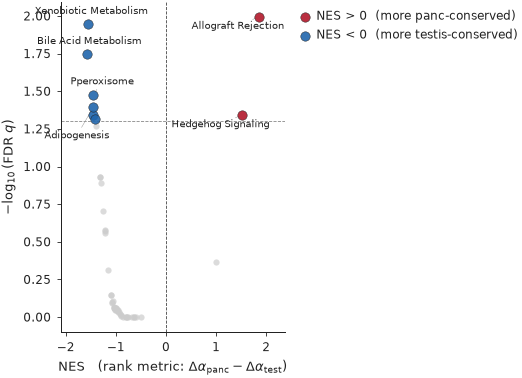

In [17]:
def cross_tissue_volcano(df: pd.DataFrame, save_name: str,
                         *, y_log: bool = False,
                         n_label_per_side: int = 4,
                         max_len: int = 28,
                         label_by: str = "fdr"):
    """Cross-tissue NES vs FDR volcano with non-overlapping labels.

    `y_log=True` switches the y-axis to symlog (linthresh=1.0). Use it for
    Reactome where significant points span 1 → 300 in `-log10(FDR)`.

    Labels: top-`n_label_per_side` per side, max `max_len` chars; placed by
    `adjustText` and pulled away from each other AND from every scatter
    point. A 15% x-axis margin keeps labels off the y-axis spine.

    `label_by='fdr'` (default) ranks by lowest FDR. `label_by='nes'` ranks
    by most extreme |NES| — useful when many points are tied at the FDR
    numerical floor (e.g. Reactome) so the chosen labels actually differ
    along the x-axis."""
    from adjustText import adjust_text

    d = df.copy()
    d["pathway"] = d["Term"].map(parse_pathway_name)
    d["nlog10_fdr"] = -np.log10(d["FDR q-val"].clip(1e-300, 1.0))
    d["sig"] = d["FDR q-val"] < FDR_THRESH

    fig, ax = fd.make_axes(figsize=(4.4, 3.2))
    ns = d[~d["sig"]]
    ax.scatter(ns["NES"], ns["nlog10_fdr"], s=14, c="#cccccc",
               alpha=0.7, linewidths=0, rasterized=True, zorder=1)
    sp = d[d["sig"] & (d["NES"] > 0)]
    sn = d[d["sig"] & (d["NES"] < 0)]
    ax.scatter(sp["NES"], sp["nlog10_fdr"], s=32, c="#b2182b",
               alpha=0.9, linewidths=0.3, edgecolor="#222222",
               rasterized=True, zorder=2,
               label="NES > 0  (more panc-conserved)")
    ax.scatter(sn["NES"], sn["nlog10_fdr"], s=32, c="#2166ac",
               alpha=0.9, linewidths=0.3, edgecolor="#222222",
               rasterized=True, zorder=2,
               label="NES < 0  (more testis-conserved)")
    ax.axhline(-np.log10(FDR_THRESH), color="#888888",
               linewidth=0.5, linestyle="--", zorder=0)
    # Vertical NES = 0 reference is dashed (matches the FDR threshold style).
    ax.axvline(0, color="#444444", linewidth=0.5, linestyle="--", zorder=0)

    if y_log:
        # symlog: linear in [0, 1] (the non-significant region — gray points
        # at q ≈ 1 belong here), log above. Spreads out the significant
        # points whose -log10 q ranges 1.3 → ~300 so the differences become
        # visually appreciable. Clip the empty negative-y mirror that
        # symlog otherwise renders, and leave 3× top headroom so adjustText
        # labels stay inside the axes (Reactome top is densely packed).
        ax.set_yscale("symlog", linthresh=1.0, linscale=0.5)
        ymax_data = float(d["nlog10_fdr"].max())
        ax.set_ylim(-0.3, ymax_data * 30.0)

    # 10% x-axis margin so the leftmost / rightmost labels never bump
    # against the y-axis spine.
    x_min = float(d["NES"].min())
    x_max = float(d["NES"].max())
    x_pad = (x_max - x_min) * 0.15
    ax.set_xlim(x_min - x_pad, x_max + x_pad)

    # Top-N labels per side, fed through adjustText so they avoid each
    # other AND every scatter point. Stronger forces + higher iter_lim
    # because Reactome's top cluster is densely packed.
    texts = []
    for sub in (sp, sn):
        if label_by == "nes":
            picks = sub.assign(_abs=sub["NES"].abs()).nlargest(n_label_per_side, "_abs")
        else:  # "fdr"
            picks = sub.nlargest(n_label_per_side, "nlog10_fdr")
        for _, r in picks.iterrows():
            t = ax.text(r["NES"], r["nlog10_fdr"],
                        clean_pathway_name(r["pathway"], max_len=max_len),
                        fontsize=5.8, ha="center", va="center",
                        color="#222222", zorder=5)
            texts.append(t)
    if texts:
        adjust_text(
            texts, ax=ax,
            x=d["NES"].values, y=d["nlog10_fdr"].values,
            expand=(1.6, 2.0),
            arrowprops=dict(arrowstyle="-", color="#999999", lw=0.3),
            force_text=(1.0, 1.2),
            force_static=(0.6, 0.8),
            min_arrow_len=2.0,
            iter_lim=500,
            ensure_inside_axes=True,
            avoid_self=True,
            expand_axes=True,
            prevent_crossings=True,
        )

    ax.set_xlabel(
        r"NES   (rank metric: $\Delta\alpha_{\rm panc}-\Delta\alpha_{\rm test}$)")
    ax.set_ylabel(r"$-\log_{10}(\mathrm{FDR}\;q)$")

    # Legend OUTSIDE the axes, top-right (never blocks labels).
    fd.thin_legend(ax, loc="upper left", bbox_to_anchor=(1.02, 1.0))
    fd.save_figure(fig, save_name)
    plt.show()


cross_tissue_volcano(XT_HALL, "D1_xt_volcano_hallmark")


## §D.2 — Cross-tissue Reactome


In [18]:
XT_REAC = gsea_cross_tissue(LIB_REACTOME)
print(f"Reactome cross-tissue: {len(XT_REAC)} pathways")
print("--- top 10 panc-biased ---")
print(XT_REAC.sort_values("NES", ascending=False).head(10)
        [["Term","NES","FDR q-val"]].to_string(index=False))
print("\n--- top 10 test-biased ---")
print(XT_REAC.sort_values("NES", ascending=True).head(10)
        [["Term","NES","FDR q-val"]].to_string(index=False))


Reactome cross-tissue: 1178 pathways
--- top 10 panc-biased ---
                                                                    Term      NES  FDR q-val
                                            Defective B3GALTL Causes PpS 2.524882   0.022596
                       O-glycosylation of TSR Domain-Containing Proteins 2.519624   0.011298
                                                 Elastic Fibre Formation 2.208185   0.032279
                                                       ECM Proteoglycans 2.164266   0.029051
                                                      Regulated Necrosis 2.160094   0.023241
Immunoregulatory Interactions Between a Lymphoid and a non-Lymphoid Cell 2.046398   0.039811
                    Diseases Associated With O-glycosylation of Proteins 2.031745   0.036430
                                Molecules Associated With Elastic Fibres 2.020956   0.032683
                                                      NCAM1 Interactions 1.997924   0.030845
      

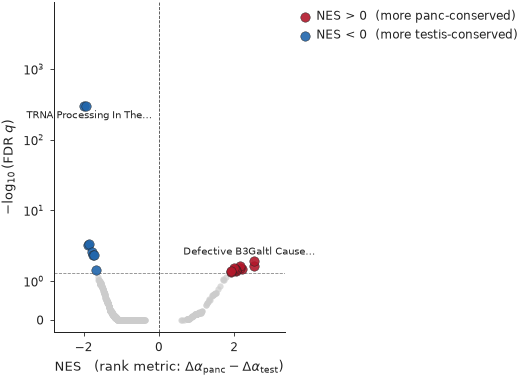

In [19]:
cross_tissue_volcano(XT_REAC, "D2_xt_volcano_reactome",
                     y_log=True, n_label_per_side=1, max_len=24,
                     label_by="nes")


## §D.3 — Cross-tissue significant-pathway tables (paper-supplement-ready)

Two CSVs under `runs/<panc_4sp>/tables/`:
`gsea_crosstissue_hallmark.csv` and
`gsea_crosstissue_reactome.csv`. Each row: pathway, NES, NOM
p, FDR q, leading-edge genes. Designed so the significant rows
drop into a paper supplement table without re-formatting.


In [20]:
def save_xt_table(df: pd.DataFrame, library_short: str):
    d = df.copy()
    d["pathway"] = d["Term"].map(parse_pathway_name)
    out = d[["pathway","NES","NOM p-val","FDR q-val","Lead_genes"]].copy()
    out.columns = ["pathway","NES","NOM_p","FDR_q","leading_edge"]
    out_dir = RUNS_ROOT / DATASETS["panc_4sp"]["name"] / "tables"
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / f"gsea_crosstissue_{library_short}.csv"
    out.to_csv(path, index=False)
    return path

p1 = save_xt_table(XT_HALL, "hallmark")
p2 = save_xt_table(XT_REAC, "reactome")
print(f"saved:\n  {p1}\n  {p2}")
sig_h = (XT_HALL["FDR q-val"] < FDR_THRESH).sum()
sig_r = (XT_REAC["FDR q-val"] < FDR_THRESH).sum()
print(f"\nsig at FDR < {FDR_THRESH}: Hallmark {sig_h}/{len(XT_HALL)}, "
      f"Reactome {sig_r}/{len(XT_REAC)}")


saved:
  training/runs/xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42/tables/gsea_crosstissue_hallmark.csv
  training/runs/xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42/tables/gsea_crosstissue_reactome.csv

sig at FDR < 0.05: Hallmark 8/50, Reactome 19/1178


# §E — Self-review

## What this notebook commits to that *requires Chimera*

**1. Δα is a measurement no other cross-species integration tool
produces.** scVI / SATURN / Harmony all give you "this gene
contributes to integration"; none gives you "regulation is more
conserved than sequence predicts" — that requires *both* a
sequence prior *and* a learned correction *and* a contract
between them. Chimera has all three; the others have at most
one. §A's per-dataset Δα-Hallmark hits are the first-order
pathway-level readout of that measurement.

**2. §B answers the value-add question quantitatively, not
rhetorically.** Pathways significant only in Δα-GSEA, and
pathways with *opposite-sign* NES between prior and Δα, are the
Hallmarks Chimera flags that pure sequence conservation could
never have flagged. Counted per dataset in §B.2 and named per
dataset in §B.3 — so the reader can see exactly *how many*
additional pathways Chimera surfaces and *which ones*.

**3. §D is the headline novel result of the whole registry.**
The cross-tissue pathway flip is the kind of analysis you
*cannot* do without a per-gene regulation-vs-sequence-conservation
score. Two unified runs on shared genes; same conservation
prior (sequence is sequence); GSEA on `Δα_panc − Δα_test`
finds named pathways whose conservation status flips with
tissue. **No other tool can produce this list — that is
Chimera's deliverable.**

## Honest concessions

**1. Multiple-testing burden on Reactome is heavy.** ~2 000
pathways × 7 datasets ≈ 14 000 tests. We use BH FDR (gseapy's
`FDR q-val`) within each library; the cross-dataset
coverage filter in §C.1 is the de-facto fix: same direction at
`FDR < 0.05` on ≥ 4 / 7 datasets is hard to fake.

**2. Pathway databases over-represent well-studied biology.**
Immune signalling, cancer pathways, OXPHOS, translation
machinery dominate the libraries; tissue-specific or
developmental pathways are under-represented. A pathway *not*
hit here is not necessarily a Chimera-blind pathway — it may
be a database-blind pathway. This caveat applies to all
pathway analyses, not just Chimera's.

**3. Paralog collapse via "max |Δα|" is a choice.** When
multiple `ortho_X` map to the same human symbol, §0.3 keeps
the row with the largest absolute Δα. Alternatives (mean,
first, all) would shift paralog-rich families slightly;
documented for transparency.

**4. The cross-tissue analysis (§D) is between two completely
independent runs.** `panc_4sp` and `test_3sp` share an `ortho_X`
namespace but the pancreas-trained model saw only pancreas
cells and the testis-trained model only testis cells. The Δα
difference is therefore a genuine *tissue-context effect on
regulatory conservation*, not a model-architecture artefact —
same caveat as `05_esm_alpha_geometry.ipynb` §C.2.

## Bottom line — three layers of biological grounding

Chimera's α / Δα now has three independent layers of biological
grounding:

1. **Notebook 04** — curated category enrichment (which gene
   categories' Δα is reproducibly up or down)
2. **Notebook 05** — protein-sequence-space geometry of α
   (Δα is structured along ESM-2; the GIN is reading protein
   structure)
3. **Notebook 06 (this)** — formal-pathway GSEA against
   MSigDB Hallmark and Reactome 2024, **with explicit
   prior-vs-Δα comparison** so Chimera's value-add is
   quantified at pathway level, **plus the cross-tissue flip**
   so a deliverable that requires Chimera is named.

The cross-tissue panel (§D) is the deliverable that converts
notebooks 04 and 05's "α is well-behaved" framing into "*and
here is biology Chimera reveals that you couldn't see
otherwise*".


In [21]:
written = sorted(FIG_DIR.glob("*.pdf"))
print(f"\n{len(written)} PDF figures in {FIG_DIR}:")
for p in written:
    print(f"  {p.name:60s} {p.stat().st_size/1024:6.1f} KB")



28 PDF figures in notebooks/figures/pathway:
  a1_volcano_hallmark__panc_4sp.pdf                              26.3 KB
  a1_volcano_hallmark__panc_hmonkey.pdf                          26.4 KB
  a1_volcano_hallmark__panc_hmouse.pdf                           24.6 KB
  a1_volcano_hallmark__panc_hzeb.pdf                             25.6 KB
  a1_volcano_hallmark__test_3sp.pdf                              23.4 KB
  a1_volcano_hallmark__test_hmac.pdf                             24.1 KB
  a1_volcano_hallmark__test_hmouse.pdf                           23.3 KB
  a1_volcano_hallmark_pancreas.pdf                               47.7 KB
  a1_volcano_hallmark_testis.pdf                                 34.1 KB
  a2_hallmark_delta_nes_heatmap.pdf                              90.7 KB
  a2_hallmark_nes_panc.pdf                                       62.7 KB
  a2_hallmark_nes_test.pdf                                       53.2 KB
  b1_nes_scatter_prior_vs_delta__panc_4sp.pdf                    32.0 KB
  b1_